# Texas early voting: 2026 vs 2024, by how precincts voted in 2024

This notebook compares **early in-person voting in Texas so far in 2026** with the **same point in 2024**, precinct by precinct. Precincts are lined up by how they voted for president in 2024.

**The question.** Is 2026 early turnout keeping pace with 2024 evenly across Texas, or is it running higher in some kinds of precincts than in others?

**The measure.** For each precinct: 2026 early in-person ballots ÷ 2024 early in-person ballots, both counted through the same day of early voting. 100% means the same pace as 2024. The notebook calls this figure **turnout vs 2024**. Whenever precincts are grouped, it is summed 2026 ballots ÷ summed 2024 ballots, so each precinct counts in proportion to its size.

**Keep in mind.** 2026 is a midterm and 2024 was a presidential election, so fewer ballots overall is expected. The interesting part is whether the shortfall is the same everywhere.

**The data.** Precinct counts and the 2024↔2026 precinct matching come from Jackson Hannan's [Texas early-vote comparison dashboard](https://jacksonahannan.github.io/early-vote-dashboard/). It compiles Texas Secretary of State and county early-vote reports. It attaches 2024 presidential results by precinct from certified county canvasses in 14 counties and from the Texas Legislative Council everywhere else. A copy of that data, through early-voting day 11 (Thursday, October 29, 2026), is embedded in this notebook, so the main analysis runs without internet access and reproduces the saved results. Step 5 adds two Texas Legislative Council tables by precinct: 2020 Census population and 2024 voter registration. The notebook downloads them on its first run, caches them, and checks them against pinned fingerprints.

**The projection.** Appendix C turns the turnout pattern into statewide results with a Monte Carlo simulation. The projection takes vote choice from late-October polling averages, including the third-party candidates; a separate reference scenario shows what turnout alone would do if people voted as they did in 2024. Turnout counts cannot show how anyone voted, so both rest on assumptions, all written out there. Everything before Appendix C describes turnout only.

**What it can't tell you.** How anyone voted. A precinct Harris won in 2024 still contains Trump voters, and the reverse. This covers early in-person ballots only, with no mail ballots and no Election Day. Not every precinct can be matched between years. Texas does not record voters' race or ethnicity, so Step 5 describes precincts by who lives or is registered there, not by who voted. No voter-level records are downloaded or stored at any point.

*Opening in nteract: it will ask you to approve the pinned Python packages the first time. Save the notebook to a folder before running it; it reads its embedded data from the saved file.*

*License: BSD 3-Clause, © 2026 Greg Jennings (full text at the end). Data sources are credited in "Saved files, sources and credits".*

In [1]:
from IPython.display import Markdown, display

summary_slot = display(
    Markdown("_The summary appears here once the notebook has finished running._"),
    display_id=True,
)

**Summary (early-voting day 11: 2026 through Oct 29 vs 2024 through Oct 31)**

- **Overall:** compared precincts have cast **84%** as many early in-person ballots as at this point in 2024.
- **By 2024 vote:** Trump-won precincts are at **79%** of their 2024 pace, Harris-won precincts at **91%**. By fifths of 2024 early voters, from most Trump to most Harris: 72%, 79%, 86%, 89%, 93%.
- **Where ballots come from (where they were cast, not how):** Trump-won precincts cast 64% of 2024's early ballots at this point and 60% of 2026's.
- **One number:** +3.9 points of turnout vs 2024 per +10 points of 2024 Harris share (95% range +3.5 to +4.3); +3.3 comparing precincts within the same county.
- **By Hispanic share (Step 5):** precincts in the least Hispanic fifth are at 79% of their 2024 pace, the most Hispanic fifth at 91% (Spanish-surname share of registered voters). Holding the 2024 vote fixed: +1.4 points of turnout vs 2024 per +10 points of Spanish-surname share.
- **The projection, vote choice from the polls (Appendix C; polls as of 2026-10-30):** U.S. Senate: polls put the Democrat at 51.7% of the two-party vote (+8.6 from 2024, split into G +1.4, I +4.3, T +0.3, R +2.6); the Democratic candidate wins 75% of simulations, the Republican 25%. Of all votes, including third-party candidates: Democrat 50.1%, Republican 46.8%, third party 3.1%. Governor: polls put the Democrat at 48.6% of the two-party vote (+5.6 from 2024, split into G +1.4, I +3.0, T +0.1, R +1.1); the Democratic candidate wins 29% of simulations, the Republican 71%. Of all votes, including third-party candidates: Democrat 47.5%, Republican 50.2%, third party 2.3%.
- **Reference scenario, if people vote as in 2024 (Appendix C):** turnout alone moves the statewide Democratic two-party share +1.4 points from 2024's 43.1%, to a median of 44.4%. The Democratic candidate is ahead in 6% of simulations and the Republican in 94%; an even race would need a uniform swing of +5.5 points toward Democrats.
- **Coverage:** 5,589 precinct groups in 213 counties, 73% of Texas's 2024 Harris + Trump vote. In 2024 Harris won 43% of that vote in the compared precincts and 43% in the rest of Texas, so these figures describe the compared precincts, not the whole state. Large counties not compared on this day: Dallas, Guadalupe, Taylor. Data: pinned snapshot, sha256 fcc036b1ee24.
- **Limits:** places, not people; turnout, not vote choice (the projection and the reference scenario rest on their stated assumptions); 2026 is a midterm and 2024 was a presidential year; early in-person ballots only; day 11 of 12, so the numbers will move.


## Settings

The defaults reproduce the saved results. Only Step 5 needs internet access, and only on the first run; it caches what it downloads in `data/cache/`.

Set `REFRESH_DATA = True` to download the latest published early-vote data instead; the numbers will then change. The other settings switch which precincts are compared, the data-quality screen, the chart spacing and Step 5. The scenario model's assumptions are set at the top of its own code cell in Appendix C.

In [2]:
import os
from pathlib import Path

# --- Data ---------------------------------------------------------------------
# False: use the day-11 snapshot embedded in this notebook (reproducible, no internet).
# True: download the latest published snapshot; results will differ from the saved ones.
REFRESH_DATA = False
PINNED_SNAPSHOT_SHA256 = (
    "fcc036b1ee249f8b389f5948d47dfd027cc767b86eab48da3e8017aa392a1c85"
)
# None = latest day in the data (day 11 in the embedded snapshot).
EARLY_VOTING_DAY = None

# --- Which precincts to compare ------------------------------------------------
# "matched": every comparable precinct or merged precinct group.
# "unchanged": only precincts whose boundaries did not change.
COHORT = "matched"
# Drop precinct groups whose 2024 counts are implausible (see Step 1).
APPLY_QC = True
QC_MIN_EV_2024 = 25  # minimum 2024 early in-person voters
# 2024 early ballots / 2024 Harris+Trump votes must be at least this fraction of the day's
# typical (median) value, which is about 30% on day 11, and at most QC_EV_SHARE_MAX.
QC_EV_SHARE_FLOOR_VS_MEDIAN = 0.44
QC_EV_SHARE_MAX = 1.05
QC_MAX_COUNTY_MAD_Z = 5.0  # how far out of line with its county a precinct may be

# --- Charts --------------------------------------------------------------------
# "voters": each precinct's width is its 2024 early voters. "precincts": equal spacing.
X_SPACING = "voters"
# Width of the moving window behind the turnout line, in % of the x-axis.
SMOOTHING_WINDOW_PCT = 5

# --- Step 5: Hispanic makeup of precincts --------------------------------------
# Downloads two Texas Legislative Council files on first run (about 83 MB), caches the
# two small tables Step 5 needs in data/cache/, and checks them against pinned SHA-256s.
FETCH_ETHNICITY_DATA = True
# If a source file has changed since it was pinned, Step 5 stops unless this is True.
ACCEPT_CHANGED_SOURCES = False

# --- Folders -------------------------------------------------------------------
RUN_DIRECTORY = Path(os.environ.get("TEXAS_EV_DIR", Path.cwd())).resolve()
NOTEBOOK_FILENAME = "texas_early_vote_2026_vs_2024.ipynb"
DATA_DIRECTORY = RUN_DIRECTORY / "data"
PARQUET_PATH = DATA_DIRECTORY / "texas_precinct_ev.parquet"
OUTPUT_ROOT = RUN_DIRECTORY / "analysis_outputs"


def shown(path):
    """A path for printing, with the home folder shortened to ~, so that saved outputs
    do not carry the user name of whoever ran the notebook."""
    path = Path(path)
    try:
        return str(Path("~") / path.relative_to(Path.home()))
    except ValueError:
        return str(path)


print("Working folder:", shown(RUN_DIRECTORY))

Working folder: ~/Downloads/texas_early_vote


### Data code (safe to skip)

The collapsed cell below holds the code that rebuilds the dataset from the published dashboard when `REFRESH_DATA = True`, the code that unpacks the embedded copy, and the 2024 county vote totals used for the coverage check in Step 1. It handles precinct and county totals only. Click to expand it if you want to review it.

In [3]:
"""Build the aggregate Texas precinct early-vote table from the published dashboard snapshot.

Only precinct totals are handled. No voter-level records are downloaded or stored.
The download functions run only when REFRESH_DATA = True; the default run unpacks the
snapshot embedded in this notebook instead. The county vote table at the end of this
cell (used for the coverage check in Step 1) is used on every run.
"""

from __future__ import annotations

import base64
import collections
import concurrent.futures
import datetime as dt
import gzip
import hashlib
import json
import urllib.request
from pathlib import Path

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

DASHBOARD = "https://jacksonahannan.github.io/early-vote-dashboard/"
ORIGINAL_COUNTIES = {
    "travis",
    "dallas",
    "montgomery",
    "bell",
    "hays",
    "ellis",
    "mclennan",
    "hockley",
    "madison",
}

TLC_RETURNS = "https://data.capitol.texas.gov/dataset/35b16aee-0bb0-4866-b1ec-859f1f044241/resource/e1cd6332-6a7a-4c78-ad2a-852268f6c7a2/download/2024-general-vtds-election-data.zip"

TLC_PRECINCTS = "https://data.capitol.texas.gov/dataset/precincts"

ROUTES = {
    "data": "/api/data",
    "reference": "/api/reference",
    "demographics": "/api/demographics",
    "completeness": "/api/completeness",
    "statewide": "/api/statewide?method=in_person",
}


def utc_now():
    return dt.datetime.now(dt.timezone.utc).isoformat()


def sha256(data):
    return hashlib.sha256(data).hexdigest()


def atomic_bytes(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_bytes(data)
    tmp.replace(path)


def fetch_bytes(url, data=None, timeout=35):
    req = urllib.request.Request(
        url, data=data, headers={"User-Agent": "TexasPrecinctResearch/1.0"}
    )
    with urllib.request.urlopen(req, timeout=timeout) as response:
        return response.read()


def pull_snapshot(raw_dir):
    raw_dir = Path(raw_dir)
    raw_dir.mkdir(parents=True, exist_ok=True)
    stamp = str(int(dt.datetime.now().timestamp()))
    pub = fetch_bytes(DASHBOARD + "publication.json?check=" + stamp)
    manifest_bytes = fetch_bytes(DASHBOARD + "api-manifest.json?check=" + stamp)
    manifest = json.loads(manifest_bytes)
    atomic_bytes(raw_dir / "publication.json", pub)
    atomic_bytes(raw_dir / "api-manifest.json", manifest_bytes)

    def one(item):
        name, route = item
        url = DASHBOARD + manifest["routes"][route]
        wire = fetch_bytes(url)
        body = gzip.decompress(wire) if wire[:2] == b"\x1f\x8b" else wire
        payload = json.loads(body)
        atomic_bytes(raw_dir / (name + ".json.gz"), gzip.compress(body, mtime=0))
        return (
            name,
            payload,
            {
                "name": name,
                "route": route,
                "url": url,
                "wire_sha256": sha256(wire),
                "json_sha256": sha256(body),
                "retrieved_at_utc": utc_now(),
            },
        )

    with concurrent.futures.ThreadPoolExecutor(max_workers=5) as pool:
        results = list(pool.map(one, ROUTES.items()))
    payloads = {name: payload for name, payload, record in results}
    inventory = [record for name, payload, record in results]
    if payloads["data"]["generated_at"] != manifest["generated_at"]:
        raise ValueError(
            "Published manifest and precinct snapshot have different generations"
        )
    inventory_doc = {
        "retrieved_at_utc": utc_now(),
        "publication": json.loads(pub),
        "manifest_generated_at_utc": manifest["generated_at"],
        "files": inventory,
    }
    atomic_bytes(
        raw_dir / "download_inventory.json",
        json.dumps(inventory_doc, indent=2).encode(),
    )
    return payloads, inventory_doc


def read_snapshot(raw_dir):
    raw_dir = Path(raw_dir)
    payloads = {
        name: json.loads(gzip.decompress((raw_dir / (name + ".json.gz")).read_bytes()))
        for name in ROUTES
    }
    return payloads, json.loads((raw_dir / "download_inventory.json").read_text())


def source_catalog(snapshot):
    records = []
    for county in snapshot["data"]["counties"]:
        for source in county["sources"]:
            row = {k: v for k, v in source.items() if k != "counts"}
            row["county_id"] = county["id"]
            row["source_id"] = sha256(
                json.dumps(row, sort_keys=True, default=str).encode()
            )[:24]
            records.append(row)
    return records


def build_published_rows(snapshot):
    data = snapshot["data"]
    refs = {c["id"]: c for c in snapshot["reference"]}
    demos = snapshot["demographics"]["counties"]
    sources = source_catalog(snapshot)
    by_county = collections.defaultdict(list)
    for s in sources:
        by_county[s["county_id"]].append(s)
    rows = []
    coverage = []
    for c in data["counties"]:
        ref = refs[c["id"]]
        pr = ref["presidential"]
        meta = ref["references"]
        for period in c["periods"]:
            cover = {
                "provider": "published_dashboard",
                "county_id": c["id"],
                "county": c["name"],
                "state_id": ref.get("state_id"),
                "early_voting_day": period["day"],
                "date_2026": period["through_2026"],
                "date_2024": period["through_2024"],
                "source_status": c["status"],
                "source_error": c.get("error"),
                "paired_group_votes_2024": period["county_2024"],
                "paired_group_votes_2026": period["county_2026"],
                **period.get("coverage", {}),
            }
            coverage.append(cover)
            lineage = {
                year: [
                    s
                    for s in by_county[c["id"]]
                    if s.get("date", "").startswith(str(year))
                    and s["date"] <= period[f"through_{year}"]
                ]
                for year in (2024, 2026)
            }
            for g in period["groups"]:
                old, new = g["old"], g["new"]
                key = sha256(json.dumps([c["id"], sorted(old), sorted(new)]).encode())[
                    :24
                ]
                complete = all(p in pr for p in old)
                hv = sum(pr[p]["harris"] for p in old) if complete else None
                tv = sum(pr[p]["trump"] for p in old) if complete else None
                # Preserve undefined observations; do not turn source placeholder zeroes into turnout.
                available = bool(g.get("available", True))
                v24 = g["votes_2024"] if available else None
                v26 = g["votes_2026"] if available else None
                dp = [
                    demos.get(c["id"], {}).get("precincts", {}).get(p, {}).get("counts")
                    for p in new
                ]
                pop_complete = all(p is not None for p in dp)
                population = sum(p["population"] for p in dp) if pop_complete else None
                vap = sum(p["vap"] for p in dp) if pop_complete else None
                denom = (hv + tv) if complete else None
                qualification = meta.get("presidential", {}).get("qualification")
                r = {
                    "provider": "published_dashboard",
                    "county_id": c["id"],
                    "county": c["name"],
                    "county_state_id": ref.get("state_id"),
                    "comparison_group_id": key,
                    "precinct_ids_2024": list(old),
                    "precinct_ids_2026": list(new),
                    "n_precincts_2024": len(old),
                    "n_precincts_2026": len(new),
                    "precinct_id": new[0] if len(old) == len(new) == 1 else None,
                    "early_voting_day": period["day"],
                    "date_2024": period["through_2024"],
                    "date_2026": period["through_2026"],
                    "voting_method": "early_in_person",
                    "ev_2024": v24,
                    "ev_2026": v26,
                    "paired_available": available,
                    "unchanged_precinct": bool(g["unchanged"]),
                    "source_partisan_bucket": g.get("bucket"),
                    "source_group_note": g.get("reason", ""),
                    "presidential_reference_complete": complete,
                    "harris_votes_2024": hv,
                    "trump_votes_2024": tv,
                    "voters_2024_two_party": denom,
                    "harris_share_2024_pct": 100 * hv / denom
                    if denom and denom > 0
                    else None,
                    "turnout_ratio_pct": 100 * v26 / v24
                    if available and v24 and v24 > 0
                    else None,
                    "population_2020": population,
                    "voting_age_population_2020": vap,
                    "census_count_complete": pop_complete,
                    "original_nine_counties": c["id"] in ORIGINAL_COUNTIES,
                    "county_source_status": c["status"],
                    "county_source_error": c.get("error"),
                    "county_checked_at_utc": c.get("checked_at"),
                    "snapshot_generated_at_utc": data["generated_at"],
                    "presidential_reference_path": meta.get("presidential", {}).get(
                        "path"
                    ),
                    "presidential_reference_sha256": meta.get("presidential", {}).get(
                        "sha256"
                    ),
                    "presidential_reference_qualification": qualification
                    or "Original county reference; see retained reference path/hash and source documents.",
                    "presidential_reference_type": (
                        "tlc_retabulated"
                        if qualification and "TLC-derived" in qualification
                        else "county_reference"
                    ),
                    "known_tlc_county_total_variance": c["id"] in {"tyler", "sherman"},
                    "crosswalk_source_path": meta.get("groups", {}).get("path"),
                    "crosswalk_sha256": meta.get("groups", {}).get("sha256"),
                    "lineage_source_ids_2024": [s["source_id"] for s in lineage[2024]],
                    "lineage_source_ids_2026": [s["source_id"] for s in lineage[2026]],
                    "source_urls_2024": sorted({s["source"] for s in lineage[2024]}),
                    "source_urls_2026": sorted({s["source"] for s in lineage[2026]}),
                    "direct_official_latest_day": False,
                }
                r["regression_eligible"] = (
                    available and bool(denom and denom > 0) and bool(v24 and v24 > 0)
                )
                rows.append(r)
    return rows, coverage, sources


DATA_DICTIONARY = {
    "provider": "Data source. This notebook uses only published_dashboard rows.",
    "comparison_group_id": "Stable hash of county and both native precinct ID sets. A matched group can contain multiple precincts.",
    "precinct_id": "Single current precinct only for a one-to-one group. Other rows retain member lists.",
    "early_voting_day": "Aligned early-voting calendar day, 1 through 12. Not an election-day forecast.",
    "ev_2024": "Cumulative early in-person ballots through date_2024, on comparable old geography. Null means unavailable, not zero.",
    "ev_2026": "Cumulative early in-person ballots through date_2026, on comparable current geography. Null means unavailable, not zero.",
    "harris_share_2024_pct": "100 * Harris / (Harris + Trump), using full 2024 presidential returns on the compared old geography.",
    "voters_2024_two_party": "Harris + Trump presidential votes, all voting modes. This excludes third-party votes and undervotes; it is not registered voters or total ballots cast.",
    "turnout_ratio_pct": "100 * ev_2026 / ev_2024. Defined only for a positive available 2024 denominator.",
    "unchanged_precinct": "Source strict unchanged/usable-presidential-reference cohort. COHORT = 'unchanged' keeps only these.",
    "population_2020": "2020 Census residents on 2026-primary geography, using whole-block internal points. Not 2026 population.",
    "voting_age_population_2020": "2020 Census residents aged 18+, not citizenship-qualified or registered voters.",
    "lineage_source_ids_2024": "County/date candidate source observations up to this cutoff; detailed records in Parquet provenance. Published inputs do not expose exact row-level report contribution.",
    "lineage_source_ids_2026": "As above for 2026.",
    "source_urls_2024": "Official underlying report URLs, not claims that original bytes were independently redownloaded in this run.",
    "source_urls_2026": "Official underlying report URLs. Acquisition mode is recorded in provenance.",
    "presidential_reference_type": "Native county reference or qualified TLC VTD retabulation. County_reference can have path/hash-only original provenance.",
    "known_tlc_county_total_variance": "Sherman or Tyler: source audit identified TLC precinct sums exceeding county certified totals. Kept in the data, left out of the comparison.",
}


def write_parquet(rows, path, provenance):
    df = pd.DataFrame(rows)
    intcols = [
        "county_state_id",
        "n_precincts_2024",
        "n_precincts_2026",
        "early_voting_day",
        "ev_2024",
        "ev_2026",
        "source_partisan_bucket",
        "harris_votes_2024",
        "trump_votes_2024",
        "voters_2024_two_party",
        "population_2020",
        "voting_age_population_2020",
    ]
    for c in intcols:
        df[c] = df[c].astype("Int64")
    for c in ["date_2024", "date_2026"]:
        df[c] = pd.to_datetime(df[c]).dt.date
    df = df.sort_values(
        ["provider", "early_voting_day", "county_id", "comparison_group_id"]
    ).reset_index(drop=True)
    assert not df.duplicated(
        ["provider", "early_voting_day", "county_id", "comparison_group_id"]
    ).any()
    assert (df.loc[df.regression_eligible, "ev_2024"] > 0).all()
    assert df.loc[df.regression_eligible, "harris_share_2024_pct"].between(0, 100).all()
    table = pa.Table.from_pandas(df, preserve_index=False)
    metadata = dict(table.schema.metadata or {})
    compact = {
        k: v
        for k, v in provenance.items()
        if k not in {"source_observations", "population_sources", "reference_manifest"}
    }
    compact["full_provenance_key"] = "texas_ev.provenance_full_gzip_base64"
    metadata[b"texas_ev.provenance"] = json.dumps(
        compact, sort_keys=True, default=str
    ).encode()
    metadata[b"texas_ev.provenance_full_gzip_base64"] = base64.b64encode(
        gzip.compress(
            json.dumps(provenance, sort_keys=True, default=str).encode(), mtime=0
        )
    )
    metadata[b"texas_ev.data_dictionary"] = json.dumps(
        DATA_DICTIONARY, sort_keys=True
    ).encode()
    metadata[b"texas_ev.schema_version"] = b"1.0"
    table = table.replace_schema_metadata(metadata)
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    pq.write_table(table, tmp, compression="zstd", compression_level=7, version="2.6")
    tmp.replace(path)
    check = pq.read_table(path)
    assert check.num_rows == len(df)
    return df


def compile_snapshot(snapshot, inventory, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    rows, coverage, sources = build_published_rows(snapshot)
    provenance = {
        "prepared_at_utc": utc_now(),
        "published_generated_at_utc": snapshot["data"]["generated_at"],
        "published_through": snapshot["data"]["through"],
        "published_max_day": snapshot["data"]["days"],
        "dashboard": DASHBOARD,
        "download_inventory": inventory,
        "geography": snapshot["data"]["geography"],
        "presidential_reference_source": TLC_RETURNS,
        "precinct_boundaries_source": TLC_PRECINCTS,
        "population_method": snapshot["demographics"]["method"],
        "population_sources": snapshot["demographics"]["sources"],
        "reference_manifest": {c["id"]: c["references"] for c in snapshot["reference"]},
        "source_observations": sources,
        "official_refresh": {"status": "not_used_in_this_notebook"},
        "acquisition_note": "Published snapshot downloads were refreshed and hashed. Upstream official-report hashes are supplied by the publisher, not independently re-downloaded.",
        "lineage_note": "Published group lineage lists county reports up to each cutoff; exact group-to-report contribution is not exposed by that API.",
    }
    df = write_parquet(rows, output_dir / "texas_precinct_ev.parquet", provenance)
    pd.DataFrame(coverage).to_parquet(
        output_dir / "county_coverage.parquet", index=False, compression="zstd"
    )
    atomic_bytes(
        output_dir / "provenance.json",
        json.dumps(provenance, indent=2, default=str).encode(),
    )
    atomic_bytes(
        output_dir / "data_dictionary.json",
        json.dumps(DATA_DICTIONARY, indent=2).encode(),
    )
    return df, provenance


def refresh_and_compile(output_dir):
    """Download the latest published snapshot and rebuild the Parquet table."""
    output_dir = Path(output_dir)
    snapshot, inventory = pull_snapshot(output_dir / "raw")
    print(
        f"Published snapshot: through {snapshot['data']['through']}, {len(snapshot['data']['counties'])} counties."
    )
    return compile_snapshot(snapshot, inventory, output_dir)


# --- Unpacking the snapshot embedded in this notebook -------------------------------------------


def read_parquet_provenance(path):
    meta = pq.read_metadata(path).metadata
    compressed = meta.get(b"texas_ev.provenance_full_gzip_base64")
    if compressed:
        return json.loads(gzip.decompress(base64.b64decode(compressed)))
    return json.loads(meta[b"texas_ev.provenance"])


def extract_embedded_snapshot(destination, folder, notebook_filename, expected_sha256):
    """Write the Parquet snapshot stored in this notebook's metadata to `destination`."""
    folder = Path(folder)
    candidates = [folder / notebook_filename] + sorted(
        p for p in folder.glob("*.ipynb") if p.name != notebook_filename
    )
    for candidate in candidates:
        try:
            # Read as bytes: the file is UTF-8, and Windows' default text encoding is not.
            notebook = json.loads(candidate.read_bytes())
            attachment = (
                notebook.get("metadata", {})
                .get("texas_ev", {})
                .get("embedded_snapshot")
            )
            if not attachment:
                continue
            payload = gzip.decompress(
                base64.b64decode(attachment["parquet_gzip_base64"])
            )
        except (OSError, ValueError, KeyError):
            continue  # missing, unreadable or unrelated notebook: try the next one
        if sha256(payload) != expected_sha256:
            continue  # a different snapshot, e.g. an older copy: keep looking
        atomic_bytes(destination, payload)
        return candidate
    raise FileNotFoundError(
        f"No notebook in {folder} holds the pinned snapshot (sha256 {expected_sha256[:12]}). "
        "Save this notebook to disk, or set TEXAS_EV_DIR to the folder that holds it."
    )


# --- 2024 presidential vote by county, for the coverage table ------------------------------------
# Harris and Trump votes in every Texas county, summed from the Texas Legislative Council's 2024
# general election returns by VTD (2024_General_Election_Returns.csv inside TLC_RETURNS above).
# Format "County:Harris:Trump", with spaces in county names written as "_". Statewide these sum to
# 11,228,537 Harris + Trump votes; the official state canvass total is 11,228,847.

COUNTY_2024_HARRIS_TRUMP = (
    "Anderson:3635:15597 Andrews:806:5205 Angelina:8146:26049 Aransas:2831:10090 "
    "Archer:520:4592 Armstrong:77:1029 Atascosa:5153:13142 Austin:2816:12457 "
    "Bailey:332:1395 Bandera:2532:10939 Bastrop:15989:23301 Baylor:183:1469 "
    "Bee:2606:6111 Bell:53973:75161 Bexar:411389:337545 Blanco:1973:6447 "
    "Borden:16:370 Bosque:1524:7969 Bowie:9282:27122 Brazoria:63976:95867 "
    "Brazos:33844:56671 Brewster:1969:2545 Briscoe:72:666 Brooks:1308:1077 "
    "Brown:2131:14591 Burleson:1703:7588 Burnet:6114:21795 Caldwell:6618:8880 "
    "Calhoun:1853:5939 Callahan:761:6180 Cameron:54258:60991 Camp:1201:4011 "
    "Carson:290:2866 Cass:2406:11693 Castro:418:1594 Chambers:4187:20557 "
    "Cherokee:3744:16593 Childress:263:1991 Clay:584:5288 Cochran:148:735 "
    "Coke:179:1623 Coleman:428:3712 Collin:222115:279534 Collingsworth:135:1066 "
    "Colorado:2108:7824 Comal:27680:74756 Comanche:834:5679 Concho:153:1038 "
    "Cooke:3310:16975 Coryell:6938:16619 Cottle:89:565 Crane:186:1195 "
    "Crockett:323:1087 Crosby:451:1416 Culberson:319:451 Dallam:152:1285 "
    "Dallas:511027:322468 Dawson:667:2810 DeWitt:1270:6515 Deaf_Smith:1019:3233 "
    "Delta:397:2250 Denton:191503:250521 Dickens:146:844 Dimmit:1750:1648 "
    "Donley:174:1512 Duval:1993:2435 Eastland:912:7396 Ector:9900:32467 "
    "Edwards:133:869 El_Paso:143156:105124 Ellis:33850:64763 Erath:2871:15349 "
    "Falls:1713:4520 Fannin:2607:13648 Fayette:2515:10699 Fisher:330:1487 "
    "Floyd:358:1715 Foard:92:448 Fort_Bend:179310:173592 Franklin:813:4473 "
    "Freestone:1500:7509 Frio:1848:3060 Gaines:538:5840 Galveston:56732:100295 "
    "Garza:213:1374 Gillespie:3160:13202 Glasscock:38:623 Goliad:778:3178 "
    "Gonzales:1729:5981 Gray:845:6691 Grayson:14800:50556 Gregg:13294:33026 "
    "Grimes:2734:11197 Guadalupe:29573:54691 Hale:1903:7283 Hall:149:992 "
    "Hamilton:625:3809 Hansford:146:1842 Hardeman:188:1210 Hardin:3347:24691 "
    "Harris:808771:722695 Harrison:7369:22658 Hartley:163:1843 Haskell:312:1915 "
    "Hays:65528:58438 Hemphill:190:1412 Henderson:6919:31379 "
    "Hidalgo:104517:110760 Hill:2919:13669 Hockley:1323:6616 Hood:6051:30167 "
    "Hopkins:2917:13754 Houston:2065:7247 Howard:1759:7817 Hudspeth:272:747 "
    "Hunt:10212:36137 Hutchinson:913:7273 Irion:105:761 Jack:363:3819 "
    "Jackson:904:5360 Jasper:2615:13162 Jeff_Davis:450:699 Jefferson:38936:46596 "
    "Jim_Hogg:856:725 Jim_Wells:5577:7636 Johnson:19247:60752 Jones:907:5988 "
    "Karnes:1051:4001 Kaufman:24726:44061 Kendall:6355:22668 Kenedy:41:115 "
    "Kent:50:390 Kerr:6315:21615 Kimble:261:2126 King:6:129 Kinney:345:1062 "
    "Kleberg:4345:5614 Knox:214:1156 La_Salle:933:1417 Lamar:4079:17044 "
    "Lamb:729:3398 Lampasas:2232:8961 Lavaca:1235:9215 Lee:1640:6724 "
    "Leon:1033:7982 Liberty:5952:25241 Limestone:1921:7081 Lipscomb:123:1125 "
    "Live_Oak:761:4307 Llano:2613:10902 Loving:10:86 Lubbock:37148:86547 "
    "Lynn:367:2171 Madison:964:4498 Marion:1101:3577 Martin:247:1825 "
    "Mason:434:2076 Matagorda:3231:9957 Maverick:6373:9285 McCulloch:455:3033 "
    "McLennan:33863:64606 McMullen:37:448 Medina:6950:17464 Menard:170:861 "
    "Midland:11351:46944 Milam:2331:8691 Mills:310:2418 Mitchell:352:2144 "
    "Montague:1208:9825 Montgomery:82277:221964 Moore:860:4458 Morris:1312:4092 "
    "Motley:35:612 Nacogdoches:7690:17575 Navarro:4708:14983 Newton:952:4781 "
    "Nolan:1020:4048 Nueces:53248:67201 Ochiltree:269:2723 Oldham:74:895 "
    "Orange:5945:30191 Palo_Pinto:2143:11093 Panola:1905:9500 Parker:14872:75168 "
    "Parmer:368:2123 Pecos:1144:3042 Polk:4910:19216 Potter:8748:23007 "
    "Presidio:1288:686 Rains:869:5649 Randall:12935:53314 Reagan:141:800 "
    "Real:315:1625 Red_River:1103:4682 Reeves:1070:2340 Refugio:919:2134 "
    "Roberts:20:547 Robertson:1926:6177 Rockwall:18092:43542 Runnels:452:3580 "
    "Rusk:4327:17212 Sabine:590:4972 San_Augustine:809:2917 "
    "San_Jacinto:2175:10524 San_Patricio:8025:17337 San_Saba:276:2412 "
    "Schleicher:192:906 Scurry:734:4945 Shackelford:146:1565 Shelby:1741:8164 "
    "Sherman:70:817 Smith:28041:74862 Somervell:751:4493 Starr:6862:9487 "
    "Stephens:384:3368 Sterling:43:583 Stonewall:108:603 Sutton:228:1167 "
    "Swisher:403:1840 Tarrant:384501:426626 Taylor:13624:41198 Terrell:91:314 "
    "Terry:587:2815 Throckmorton:73:823 Titus:2275:7861 Tom_Green:11585:33399 "
    "Travis:398968:170781 Trinity:1192:6121 Tyler:1252:8327 Upshur:2820:16939 "
    "Upton:146:1149 Uvalde:3218:6482 Val_Verde:5282:9162 Van_Zandt:3450:24351 "
    "Victoria:9998:25010 Walker:7461:17515 Waller:10183:17077 Ward:627:3115 "
    "Washington:4058:14020 Webb:31996:33397 Wharton:3910:12439 Wheeler:169:2093 "
    "Wichita:12237:31818 Wilbarger:860:3566 Willacy:2673:2856 "
    "Williamson:147766:155310 Wilson:6247:20894 Winkler:283:1646 Wise:5605:32385 "
    "Wood:3618:20621 Yoakum:342:2039 Young:962:7298 Zapata:1877:2970 "
    "Zavala:1984:1480"
)
COUNTY_2024_HARRIS_TRUMP_SHA256_PREFIX = "4c21e7fa16d7"


def county_name_key(name):
    """'Fort Bend', 'FORT_BEND' and 'fortbend' all become 'fortbend'."""
    return "".join(ch for ch in str(name).lower() if ch.isalpha())


def county_2024_votes():
    """2024 Harris and Trump votes for all 254 counties, indexed by county_name_key."""
    digest = sha256(COUNTY_2024_HARRIS_TRUMP.encode())[:12]
    if digest != COUNTY_2024_HARRIS_TRUMP_SHA256_PREFIX:
        raise ValueError(
            "COUNTY_2024_HARRIS_TRUMP was edited: its checksum no longer matches."
        )
    rows = [token.split(":") for token in COUNTY_2024_HARRIS_TRUMP.split()]
    table = pd.DataFrame(rows, columns=["county", "harris", "trump"])
    table["county"] = table.county.str.replace("_", " ")
    table[["harris", "trump"]] = table[["harris", "trump"]].astype(int)
    table["two_party"] = table.harris + table.trump
    assert len(table) == 254 and table.two_party.sum() == 11_228_537
    return table.set_index(table.county.map(county_name_key).rename("county_key"))

In [4]:
import importlib.metadata
import sys

import numpy as np
import pandas as pd

PINNED_VERSIONS = {
    "python": "3.12.12",
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "pyarrow": "19.0.1",
    "matplotlib": "3.10.8",
    "scipy": "1.17.0",
    "statsmodels": "0.14.6",
}
mismatches = []
for package, pinned in PINNED_VERSIONS.items():
    running = (
        sys.version.split()[0]
        if package == "python"
        else importlib.metadata.version(package)
    )
    if running != pinned:
        mismatches.append(f"{package} {running} (pinned {pinned})")
if mismatches:
    print(
        "Note: package versions differ from the pins; results may differ in the last decimal:",
        "; ".join(mismatches),
    )

load_mode = "pinned_snapshot"
if REFRESH_DATA:
    try:
        refresh_and_compile(DATA_DIRECTORY)
        load_mode = "refreshed_published_snapshot"
    except Exception as error:
        print(
            f"Refresh failed ({type(error).__name__}: {error}). Using the pinned snapshot instead."
        )
        load_mode = "fallback_to_pinned"
if load_mode != "refreshed_published_snapshot":
    extract_embedded_snapshot(
        PARQUET_PATH, RUN_DIRECTORY, NOTEBOOK_FILENAME, PINNED_SNAPSHOT_SHA256
    )

data = pd.read_parquet(PARQUET_PATH)
provenance = read_parquet_provenance(PARQUET_PATH)
data_sha256 = sha256(PARQUET_PATH.read_bytes())
print(
    f"Data: {load_mode} | published {provenance['published_generated_at_utc'][:16].replace('T', ' ')} UTC | "
    f"through {provenance['published_through']} | sha256 {data_sha256[:12]}"
)

Data: pinned_snapshot | published 2026-10-30 20:49 UTC | through 2026-10-29 | sha256 fcc036b1ee24


## Step 1: Which precincts are compared

A precinct can be compared only if both years' early ballots are reported for the same piece of ground and its full 2024 presidential result is known.

- **Matched groups.** Where precinct lines changed between 2024 and 2026, the dashboard merges neighbors into the smallest group that covers the same ground in both years. Each group counts once and keeps its combined ballots. Set `COHORT = "unchanged"` to keep only precincts whose lines did not change.
- **Two counties left out.** Tyler and Sherman are excluded because the source found their 2024 precinct sums exceed the certified county totals.
- **Data-quality screen.** A group is dropped if it had fewer than 25 early voters in 2024 (`QC_MIN_EV_2024`), or if its 2024 early ballots look implausible next to its 2024 presidential vote. That means far below what is typical for that day of early voting (`QC_EV_SHARE_FLOOR_VS_MEDIAN`; about 30% of its Harris + Trump votes on day 11), above 105% of them (`QC_EV_SHARE_MAX`), or far out of line with the rest of its county (`QC_MAX_COUNTY_MAD_Z`). These usually point to a precinct-matching or reporting problem rather than real turnout. In the embedded snapshot, for example, Johnson County precinct 10 shows 65 early voters in 2024 against 1,229 in 2026, with 2,006 Harris + Trump votes. The cell below prints how many groups each rule flagged. Set `APPLY_QC = False` to keep them all.
- **Coverage.** Some counties publish only part of their precincts, and some have no precinct data yet. The cell measures how much of each county's full 2024 Harris + Trump vote (from the Texas Legislative Council's county results) falls in compared precincts. Where a county is only partly compared, it also shows whether the compared part voted like the rest of the county in 2024. It prints the same comparison for Texas as a whole, and names any large county with no compared precincts on the chosen day.

In [5]:
X = "harris_share_2024_pct"  # 2024 Harris share of Harris + Trump votes, in %
TX_2024_TWO_PARTY_VOTES = 6_393_597 + 4_835_250  # Trump + Harris, 2024 official canvass
TX_COUNTIES = 254

published = data.loc[data.provider == "published_dashboard"]
available_days = sorted(int(d) for d in published.early_voting_day.unique())
day = available_days[-1] if EARLY_VOTING_DAY is None else int(EARLY_VOTING_DAY)
if day not in available_days:
    raise ValueError(f"EARLY_VOTING_DAY must be one of {available_days}")
day_rows = published.loc[published.early_voting_day == day].copy()
for column in ["ev_2024", "ev_2026", "voters_2024_two_party", X, "turnout_ratio_pct"]:
    day_rows[column] = day_rows[column].astype(float)

excluded_counties = day_rows.known_tlc_county_total_variance
not_comparable = ~day_rows.regression_eligible & ~excluded_counties
eligible = day_rows.loc[day_rows.regression_eligible & ~excluded_counties].copy()
if COHORT == "unchanged":
    eligible = eligible.loc[eligible.unchanged_precinct].copy()
elif COHORT != "matched":
    raise ValueError('COHORT must be "matched" or "unchanged"')


def qc_flags(frame):
    f = frame.copy()
    f["ev_share_2024"] = f.ev_2024 / f.voters_2024_two_party
    log_share = np.log(f.ev_share_2024)
    median = log_share.groupby(f.county_id).transform("median")
    mad = (log_share - median).abs().groupby(f.county_id).transform("median")
    f["ev_share_county_z"] = (log_share - median) / (1.4826 * mad.replace(0, np.nan))
    f["qc_small_2024_count"] = f.ev_2024 < QC_MIN_EV_2024
    f["qc_share_out_of_range"] = ~f.ev_share_2024.between(share_floor, QC_EV_SHARE_MAX)
    f["qc_out_of_line_with_county"] = f.ev_share_county_z.abs() > QC_MAX_COUNTY_MAD_Z
    f["qc_pass"] = ~(
        f.qc_small_2024_count | f.qc_share_out_of_range | f.qc_out_of_line_with_county
    )
    return f


# The typical 2024 early share grows through the period, so the floor scales with the day.
share_floor = (
    QC_EV_SHARE_FLOOR_VS_MEDIAN
    * (eligible.ev_2024 / eligible.voters_2024_two_party).median()
)
eligible = qc_flags(eligible)
flagged = eligible.loc[~eligible.qc_pass].copy()
sample = eligible.loc[eligible.qc_pass].copy() if APPLY_QC else eligible.copy()
assert not sample.duplicated(["county_id", "comparison_group_id"]).any()
assert sample.date_2024.nunique() == sample.date_2026.nunique() == 1
UNIT = "precinct" if COHORT == "unchanged" else "precinct group"

date_2026 = pd.Timestamp(sample.date_2026.iloc[0])
date_2024 = pd.Timestamp(sample.date_2024.iloc[0])
covered_share = sample.voters_2024_two_party.sum() / TX_2024_TWO_PARTY_VOTES
print(
    f"Early-voting day {day}: 2026 through {date_2026:%a %b %d, %Y} "
    f"vs 2024 through {date_2024:%a %b %d, %Y}."
)
print(
    f"Compared: {len(sample):,} {UNIT}s ({int(sample.n_precincts_2024.sum()):,} 2024 "
    f"precincts) in {sample.county_id.nunique()} counties. They cast {covered_share:.0%} "
    f"of Texas's 2024 Harris + Trump vote."
)
print(
    f"Not compared: {TX_COUNTIES - day_rows.county_id.nunique()} of Texas's {TX_COUNTIES} "
    f"counties have no precinct data for day {day}; {int(not_comparable.sum()):,} groups "
    f"lack one year's counts or complete 2024 returns; Tyler and Sherman "
    f"({int(excluded_counties.sum())} groups) are excluded."
)
if COHORT == "unchanged":
    print("Merged precinct groups are left out because COHORT = 'unchanged'.")

reason_columns = {
    "qc_small_2024_count": f"under {QC_MIN_EV_2024} voters in 2024",
    "qc_share_out_of_range": "implausible 2024 count",
    "qc_out_of_line_with_county": "out of line with county",
}
flagged["reason"] = [
    ", ".join(label for column, label in reason_columns.items() if row[column])
    for _, row in flagged[list(reason_columns)].iterrows()
]
print(
    f"Data-quality screen: {len(flagged)} groups flagged "
    f"({flagged.ev_2024.sum() / eligible.ev_2024.sum():.1%} of 2024 early ballots)"
    f"{' and dropped' if APPLY_QC else ' but kept (APPLY_QC = False)'}. By rule: "
    + "; ".join(
        f"{label} {int(flagged[col].sum())}" for col, label in reason_columns.items()
    )
    + f" (a group can trip more than one). Implausible means 2024 early ballots below "
    f"{share_floor:.0%} or above {QC_EV_SHARE_MAX:.0%} of 2024 Harris + Trump votes."
)
flagged_table = (
    flagged.sort_values("turnout_ratio_pct", ascending=False)
    .assign(
        precinct_ids_2024=lambda f: f.precinct_ids_2024.map(", ".join),
        precinct_ids_2026=lambda f: f.precinct_ids_2026.map(", ".join),
    )[
        [
            "county",
            "precinct_ids_2024",
            "precinct_ids_2026",
            "ev_2024",
            "ev_2026",
            "voters_2024_two_party",
            "turnout_ratio_pct",
            "reason",
        ]
    ]
    .rename(
        columns={
            "county": "County",
            "precinct_ids_2024": "2024 precincts",
            "precinct_ids_2026": "2026 precincts",
            "ev_2024": "2024 early voters",
            "ev_2026": "2026 early voters",
            "voters_2024_two_party": "2024 Harris + Trump votes",
            "turnout_ratio_pct": "2026 as % of 2024",
            "reason": "Why flagged",
        }
    )
    .round(1)
    .reset_index(drop=True)
)
display(flagged_table.head(10))

# Coverage is measured against each county's full 2024 presidential vote (all 254 counties,
# from the Texas Legislative Council table in the data code cell), not just the precincts
# the dashboard lists.
county_totals = county_2024_votes()
compared_votes = (
    sample.assign(
        key=sample.county.map(county_name_key),
        harris=sample.harris_votes_2024.astype(float),
    )
    .groupby("key")[["voters_2024_two_party", "harris"]]
    .sum()
)
unknown = sorted(set(compared_votes.index) - set(county_totals.index))
assert not unknown, f"Counties missing from the 2024 county table: {unknown}"
coverage = county_totals.join(compared_votes, how="left", rsuffix="_compared").fillna(0)
coverage["compared %"] = 100 * coverage.voters_2024_two_party / coverage.two_party
rest_of_county = coverage.two_party - coverage.voters_2024_two_party
coverage["Harris % in compared precincts"] = (
    100
    * coverage.harris_compared
    / coverage.voters_2024_two_party.where(lambda v: v > 0)
)
coverage["Harris % in the rest of the county"] = (
    100
    * (coverage.harris - coverage.harris_compared)
    / rest_of_county.where(coverage["compared %"] < 98)
)

state_harris, state_votes = county_totals.harris.sum(), county_totals.two_party.sum()
compared_harris = sample.harris_votes_2024.astype(float).sum()
compared_total = sample.voters_2024_two_party.sum()
print(
    f"Harris won {100 * compared_harris / compared_total:.1f}% of the 2024 Harris + Trump "
    f"vote in the compared precincts and "
    f"{100 * (state_harris - compared_harris) / (state_votes - compared_total):.1f}% in the "
    "rest of Texas."
)
# Large counties missing from this day's comparison, e.g. when the dashboard could not
# read a county's latest report. An earlier EARLY_VOTING_DAY may still include them.
missing_large = coverage.loc[
    (coverage["compared %"] == 0) & (coverage.two_party >= 50_000)
].sort_values("two_party", ascending=False)
if len(missing_large):
    print(
        f"Large counties with no compared precincts on day {day}: "
        + ", ".join(
            f"{row.county} ({row.two_party:,} 2024 Harris + Trump votes)"
            for row in missing_large.itertuples()
        )
        + "."
    )
print(
    "Coverage of the 12 largest counties. Where a county is only partly compared, the last "
    "two columns show whether its compared precincts voted like the rest of it in 2024:"
)
display(
    coverage.sort_values("two_party", ascending=False)
    .head(12)
    .reset_index(drop=True)[
        [
            "county",
            "two_party",
            "voters_2024_two_party",
            "compared %",
            "Harris % in compared precincts",
            "Harris % in the rest of the county",
        ]
    ]
    .rename(
        columns={
            "county": "County",
            "two_party": "2024 Harris + Trump votes",
            "voters_2024_two_party": "in compared precincts",
        }
    )
    .astype({"in compared precincts": int})
    .round(1)
)

Early-voting day 11: 2026 through Thu Oct 29, 2026 vs 2024 through Thu Oct 31, 2024.
Compared: 5,589 precinct groups (6,193 2024 precincts) in 213 counties. They cast 73% of Texas's 2024 Harris + Trump vote.
Not compared: 37 of Texas's 254 counties have no precinct data for day 11; 1,682 groups lack one year's counts or complete 2024
returns; Tyler and Sherman (24 groups) are excluded.
Data-quality screen: 60 groups flagged (0.3% of 2024 early ballots) and dropped. By rule: under 25 voters in 2024 14; implausibl
e 2024 count 17; out of line with county 43 (a group can trip more than one). Implausible means 2024 early ballots below 30% or
above 105% of 2024 Harris + Trump votes.


,County,2024 precincts,2026 precincts,2024 early voters,2026 early voters,2024 Harris + Trump votes,2026 as % of 2024,Why flagged
0,Johnson,43,"43, 44",109.0,3079.0,4278.0,2824.8,"implausible 2024 count, out of line with county"
1,Johnson,10,10,65.0,1229.0,2006.0,1890.8,"implausible 2024 count, out of line with county"
2,Johnson,28,28,70.0,821.0,1470.0,1172.9,"implausible 2024 count, out of line with county"
3,Johnson,41,41,454.0,1936.0,3275.0,426.4,"implausible 2024 count, out of line with county"
4,Johnson,5,5,383.0,1314.0,1981.0,343.1,implausible 2024 count
5,Bexar,1109,1109,11.0,35.0,17.0,318.2,under 25 voters in 2024
6,Johnson,8,8,307.0,955.0,1644.0,311.1,"implausible 2024 count, out of line with county"
7,Titus,16,16,340.0,995.0,1668.0,292.6,"implausible 2024 count, out of line with county"
8,Titus,14,14,222.0,625.0,989.0,281.5,"implausible 2024 count, out of line with county"
9,Harris,167,167,12.0,22.0,25.0,183.3,under 25 voters in 2024


Harris won 43.0% of the 2024 Harris + Trump vote in the compared precincts and 43.3% in the rest of Texas.
Large counties with no compared precincts on day 11: Dallas (833,495 2024 Harris + Trump votes), Guadalupe (84,264 2024 Harris +
 Trump votes), Taylor (54,822 2024 Harris + Trump votes).
Coverage of the 12 largest counties. Where a county is only partly compared, the last two columns show whether its compared prec
incts voted like the rest of it in 2024:


,County,2024 Harris + Trump votes,in compared precincts,compared %,Harris % in compared precincts,Harris % in the rest of the county
0,Harris,1531466,1531299,100.0,52.8,NaN
1,Dallas,833495,0,0.0,NaN,61.3
2,Tarrant,811127,324905,40.1,47.7,47.2
3,Bexar,748934,618229,82.5,55.4,52.8
4,Travis,569749,514917,90.4,69.9,71.2
5,Collin,501649,484691,96.6,44.1,49.6
6,Denton,442024,429160,97.1,43.6,34.1
7,Fort Bend,352902,338370,95.9,51.0,47.1
8,Montgomery,304241,301913,99.2,27.0,NaN
9,Williamson,303076,262705,86.7,48.6,49.7


## Step 2: Turnout so far compared with 2024, across every compared precinct

**How to read Chart 1**

- **Left to right:** every compared precinct, from the most Trump-voting in 2024 to the most Harris-voting. The top axis marks 2024 Harris share. By default each precinct takes up width in proportion to its 2024 early voters, so the bottom axis reads as a share of 2024's early electorate. Set `X_SPACING = "precincts"` for equal spacing.
- **Height:** each precinct's 2026 early in-person ballots so far, as a % of the same point in 2024. The line at 100% is 2024's pace.
- **Teal line:** a moving average across precincts with similar 2024 Harris share. Each point covers a window of `SMOOTHING_WINDOW_PCT`% of the x-axis (5% by default) and is summed 2026 ballots ÷ summed 2024 ballots, so large precincts count more.
- **Black bars:** each fifth of the x-axis, with that fifth's turnout so far.

Colors are deliberately neutral rather than party red and blue.

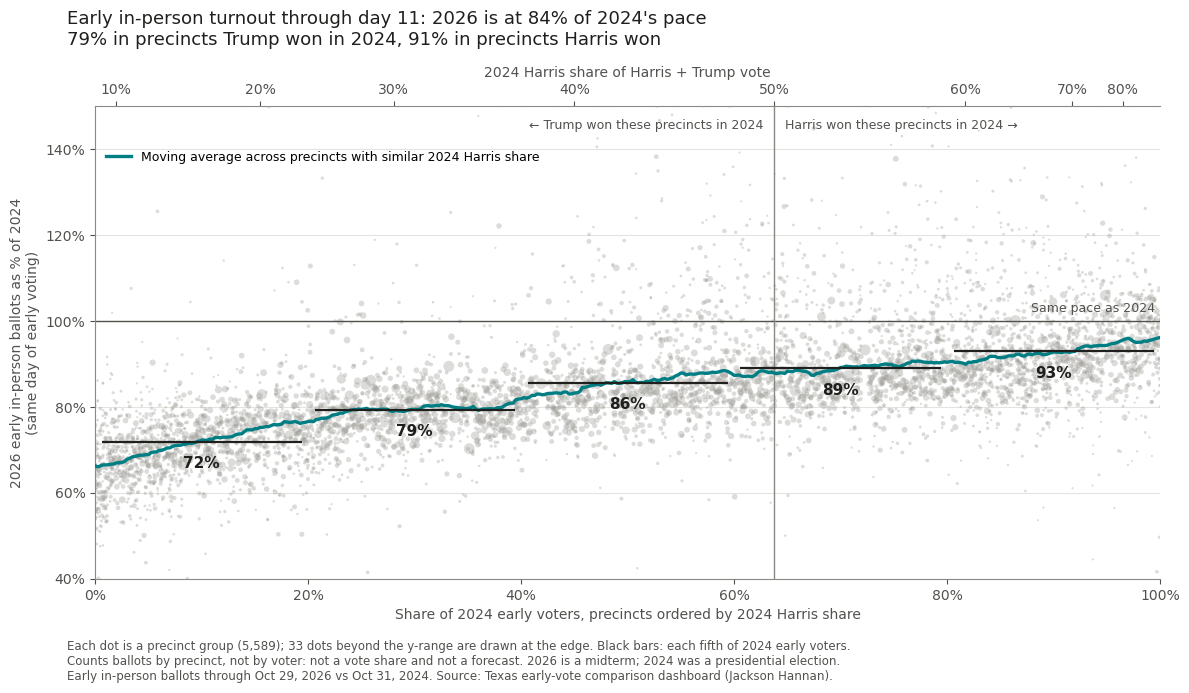

All compared precincts: 83.7% of 2024's pace. Trump-won precincts: 79.3%. Harris-won precincts: 91.3%.


,2024 Harris % from,to,precinct groups,2024 early ballots,2026 early ballots,2026 as % of 2024
Fifth of 2024 early voters,,,,,,
1,1.6,23.2,1370,1143399.0,819728.0,71.7
2,23.2,37.5,896,1144146.0,907642.0,79.3
3,37.5,48.2,896,1143247.0,978031.0,85.5
4,48.2,59.1,1091,1144371.0,1017500.0,88.9
5,59.1,95.5,1336,1143426.0,1061744.0,92.9


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Neutral colors for the turnout charts: they describe places, not parties. Party colors
# appear only where the charts show simulated election results (Charts 4 and 7).
INK, INK_2, MUTED, GRID, ACCENT, DOTS = (
    "#1f1f1d",
    "#52514e",
    "#8a8983",
    "#e4e3df",
    "#007e83",
    "#9d9c96",
)
# Democratic blue and Republican red, checked for color-blind separation.
DEM_BLUE, REP_RED = "#2166ac", "#b2182b"
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK_2,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
OUTPUT_DIRECTORY = OUTPUT_ROOT / f"{date_2026:%Y-%m-%d}_day{day:02d}"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
CAVEAT = (
    "Counts ballots by precinct, not by voter: not a vote share and not a forecast. "
    "2026 is a midterm; 2024 was a presidential election."
)
SOURCE = (
    f"Early in-person ballots through {date_2026:%b %d, %Y} vs {date_2024:%b %d, %Y}. "
    "Source: Texas early-vote comparison dashboard (Jackson Hannan)."
)


def order_precincts(frame, spacing):
    """Sort by 2024 Harris share and give each precinct a slice of the 0-100 x-axis."""
    o = frame.sort_values([X, "county_id", "comparison_group_id"]).reset_index(
        drop=True
    )
    widths = o.ev_2024.to_numpy(float) if spacing == "voters" else np.ones(len(o))
    edges = 100 * np.concatenate([[0], np.cumsum(widths)]) / widths.sum()
    o["x_left"], o["x_right"] = edges[:-1], edges[1:]
    o["x_mid"] = (o.x_left + o.x_right) / 2
    o["ratio_pct"] = 100 * o.ev_2026 / o.ev_2024
    return o


def moving_turnout(o, window_pct, points=401):
    """Summed 2026 ballots / summed 2024 ballots in a sliding window along the x-axis."""
    grid = np.linspace(0, 100, points)
    sum_2024 = np.concatenate([[0], np.cumsum(o.ev_2024.to_numpy(float))])
    sum_2026 = np.concatenate([[0], np.cumsum(o.ev_2026.to_numpy(float))])
    lo = np.searchsorted(o.x_mid.to_numpy(), grid - window_pct / 2, "left")
    hi = np.searchsorted(o.x_mid.to_numpy(), grid + window_pct / 2, "right")
    return grid, 100 * (sum_2026[hi] - sum_2026[lo]) / (sum_2024[hi] - sum_2024[lo])


def summarize_fifths(o):
    o = o.assign(fifth=np.minimum((o.x_mid // 20).astype(int), 4) + 1)
    g = o.groupby("fifth").agg(
        harris_low=(X, "min"),
        harris_high=(X, "max"),
        x_left=("x_left", "min"),
        x_right=("x_right", "max"),
        precinct_groups=(X, "size"),
        ev_2024=("ev_2024", "sum"),
        ev_2026=("ev_2026", "sum"),
    )
    g["turnout_vs_2024_pct"] = 100 * g.ev_2026 / g.ev_2024
    g["share_of_2024_ballots_pct"] = 100 * g.ev_2024 / g.ev_2024.sum()
    g["share_of_2026_ballots_pct"] = 100 * g.ev_2026 / g.ev_2026.sum()
    return g


# Fifths of 2024 early voters: used by Chart 2, Appendix B and the summary.
ordered_by_voters = order_precincts(sample, "voters")
fifths = summarize_fifths(ordered_by_voters)
# Chart 1 follows X_SPACING.
ordered = order_precincts(sample, X_SPACING)
chart_fifths = summarize_fifths(ordered)
grid, turnout_line = moving_turnout(ordered, SMOOTHING_WINDOW_PCT)

overall_pct = 100 * sample.ev_2026.sum() / sample.ev_2024.sum()
trump_won = sample[X] < 50
harris_won = sample[X] > 50  # exact 50-50 ties belong to neither
trump_won_pct = (
    100
    * sample.loc[trump_won, "ev_2026"].sum()
    / sample.loc[trump_won, "ev_2024"].sum()
)
harris_won_pct = (
    100
    * sample.loc[harris_won, "ev_2026"].sum()
    / sample.loc[harris_won, "ev_2024"].sum()
)

y_low, y_high = 40, 150
fig, ax = plt.subplots(figsize=(12, 6.4))
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
if X_SPACING == "voters":
    dot_sizes = 2 + 40 * (ordered.ev_2024 / ordered.ev_2024.quantile(0.99)).clip(
        upper=1.5
    )
else:
    dot_sizes = 4
ax.scatter(
    ordered.x_mid,
    ordered.ratio_pct.clip(y_low, y_high),
    s=dot_sizes,
    color=DOTS,
    alpha=0.35,
    lw=0,
    rasterized=True,
    zorder=1,
)
ax.axhline(100, color=INK_2, lw=1, zorder=2)
ax.text(
    99.5, 101.5, "Same pace as 2024", ha="right", va="bottom", color=INK_2, fontsize=9
)
ax.plot(
    grid,
    turnout_line,
    color=ACCENT,
    lw=2.4,
    zorder=4,
    label="Moving average across precincts with similar 2024 Harris share",
)
for fifth in chart_fifths.itertuples():
    ax.hlines(
        fifth.turnout_vs_2024_pct,
        fifth.x_left + 0.6,
        fifth.x_right - 0.6,
        color=INK,
        lw=1.6,
        zorder=5,
    )
    ax.text(
        (fifth.x_left + fifth.x_right) / 2,
        fifth.turnout_vs_2024_pct - 3.2,
        f"{fifth.turnout_vs_2024_pct:.0f}%",
        ha="center",
        va="top",
        color=INK,
        fontsize=11,
        fontweight="bold",
        zorder=6,
    )
split = ordered.loc[ordered[X] >= 50, "x_left"].min()
ax.axvline(split, color=MUTED, lw=1, zorder=2)
ax.text(
    split - 1,
    y_high - 3,
    "← Trump won these precincts in 2024",
    ha="right",
    va="top",
    color=INK_2,
    fontsize=9,
)
ax.text(
    split + 1,
    y_high - 3,
    "Harris won these precincts in 2024 →",
    ha="left",
    va="top",
    color=INK_2,
    fontsize=9,
)
ax.set_xlim(0, 100)
ax.set_ylim(y_low, y_high)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("2026 early in-person ballots as % of 2024\n(same day of early voting)")
ax.set_xlabel(
    "Share of 2024 early voters, precincts ordered by 2024 Harris share"
    if X_SPACING == "voters"
    else "Share of compared precincts, ordered by 2024 Harris share"
)
top_axis = ax.secondary_xaxis("top")
tick_values = [10, 20, 30, 40, 50, 60, 70, 80]
top_axis.set_xticks(
    [ordered.loc[ordered[X] >= t, "x_left"].min() for t in tick_values],
    [f"{t}%" for t in tick_values],
)
top_axis.set_xlabel("2024 Harris share of Harris + Trump vote", color=INK_2)
top_axis.tick_params(colors=INK_2)
top_axis.spines["top"].set_visible(True)
top_axis.spines["top"].set_color(MUTED)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.93), frameon=False, fontsize=9)
clipped = int(((ordered.ratio_pct < y_low) | (ordered.ratio_pct > y_high)).sum())
fifth_word = "2024 early voters" if X_SPACING == "voters" else "compared precincts"
fig.suptitle(
    f"Early in-person turnout through day {day}: 2026 is at {overall_pct:.0f}% of 2024's pace\n"
    f"{trump_won_pct:.0f}% in precincts Trump won in 2024, "
    f"{harris_won_pct:.0f}% in precincts Harris won",
    x=0.06,
    ha="left",
    fontsize=13,
    color=INK,
)
fig.tight_layout()
fig.text(
    0.06,
    -0.005,
    f"Each dot is a {UNIT} ({len(ordered):,}); {clipped} dots beyond the y-range are drawn "
    f"at the edge. Black bars: each fifth of {fifth_word}.\n{CAVEAT}\n{SOURCE}",
    fontsize=8.5,
    color=INK_2,
    ha="left",
    va="top",
)
fig.savefig(
    OUTPUT_DIRECTORY / "chart1_turnout_vs_2024.png", dpi=200, bbox_inches="tight"
)
fig.savefig(OUTPUT_DIRECTORY / "chart1_turnout_vs_2024.svg", bbox_inches="tight")
plt.show()

print(
    f"All compared precincts: {overall_pct:.1f}% of 2024's pace. Trump-won precincts: "
    f"{trump_won_pct:.1f}%. Harris-won precincts: {harris_won_pct:.1f}%."
)
display(
    fifths[
        [
            "harris_low",
            "harris_high",
            "precinct_groups",
            "ev_2024",
            "ev_2026",
            "turnout_vs_2024_pct",
        ]
    ]
    .rename(
        columns={
            "harris_low": "2024 Harris % from",
            "harris_high": "to",
            "precinct_groups": f"{UNIT}s",
            "ev_2024": "2024 early ballots",
            "ev_2026": "2026 early ballots",
            "turnout_vs_2024_pct": "2026 as % of 2024",
        }
    )
    .rename_axis("Fifth of 2024 early voters")
    .round(1)
)

## Step 3: Where this year's early ballots are coming from

Chart 2 asks the same question another way. Split 2024's early voters into five equal fifths, from most Trump-voting to most Harris-voting precincts. In 2024 each fifth supplied about 20% of early ballots through this day. The bars show each fifth's share of 2026's early ballots so far.

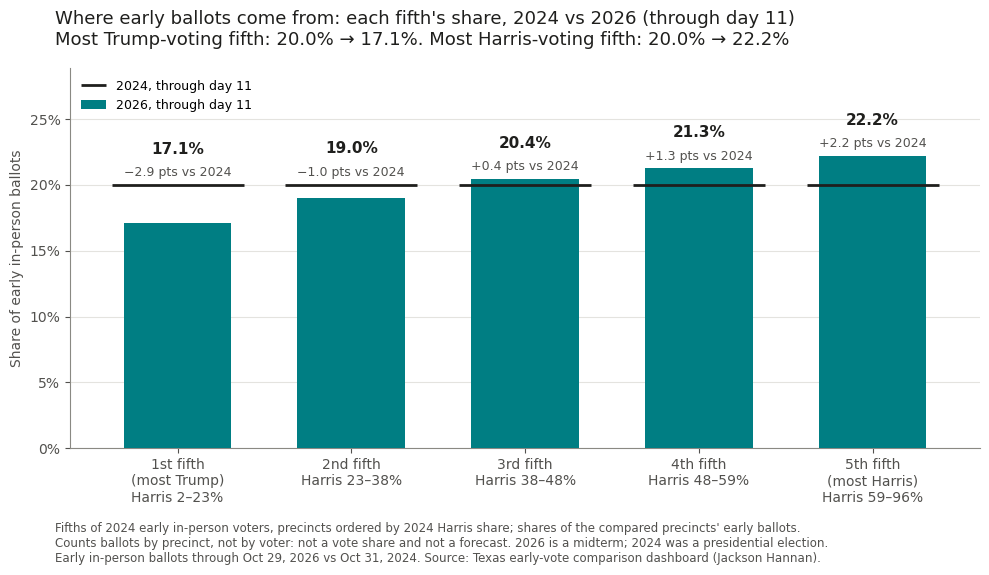

Trump-won precincts cast 63.8% of the compared early ballots at this point in 2024 and 60.5% so far in 2026.


In [7]:
trump_share_2024 = 100 * sample.loc[trump_won, "ev_2024"].sum() / sample.ev_2024.sum()
trump_share_2026 = 100 * sample.loc[trump_won, "ev_2026"].sum() / sample.ev_2026.sum()

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
positions = np.arange(len(fifths))
ax.bar(
    positions,
    fifths.share_of_2026_ballots_pct,
    width=0.62,
    color=ACCENT,
    zorder=3,
    label=f"2026, through day {day}",
)
ax.hlines(
    fifths.share_of_2024_ballots_pct,
    positions - 0.38,
    positions + 0.38,
    color=INK,
    lw=2,
    zorder=4,
    label=f"2024, through day {day}",
)
y_max = 1.3 * max(
    fifths.share_of_2026_ballots_pct.max(), fifths.share_of_2024_ballots_pct.max()
)
for i, fifth in enumerate(fifths.itertuples()):
    change = fifth.share_of_2026_ballots_pct - fifth.share_of_2024_ballots_pct
    top = max(fifth.share_of_2026_ballots_pct, fifth.share_of_2024_ballots_pct)
    ax.text(
        i,
        top + 0.075 * y_max,
        f"{fifth.share_of_2026_ballots_pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        i,
        top + 0.015 * y_max,
        f"{change:+.1f} pts vs 2024".replace("-", "−"),
        ha="center",
        va="bottom",
        fontsize=9,
        color=INK_2,
    )
names = [
    "1st fifth\n(most Trump)",
    "2nd fifth",
    "3rd fifth",
    "4th fifth",
    "5th fifth\n(most Harris)",
]
ax.set_xticks(
    positions,
    [
        f"{name}\nHarris {f.harris_low:.0f}–{f.harris_high:.0f}%"
        for name, f in zip(names, fifths.itertuples())
    ],
)
ax.set_ylim(0, y_max)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Share of early in-person ballots")
ax.legend(loc="upper left", frameon=False, fontsize=9)
first, last = fifths.iloc[0], fifths.iloc[-1]
fig.suptitle(
    f"Where early ballots come from: each fifth's share, 2024 vs 2026 (through day {day})\n"
    f"Most Trump-voting fifth: {first.share_of_2024_ballots_pct:.1f}% → "
    f"{first.share_of_2026_ballots_pct:.1f}%. Most Harris-voting fifth: "
    f"{last.share_of_2024_ballots_pct:.1f}% → {last.share_of_2026_ballots_pct:.1f}%",
    x=0.06,
    ha="left",
    fontsize=13,
    color=INK,
)
fig.tight_layout()
fig.text(
    0.06,
    -0.005,
    "Fifths of 2024 early in-person voters, precincts ordered by 2024 Harris share; "
    "shares of the compared precincts' early ballots.\n" + CAVEAT + "\n" + SOURCE,
    fontsize=8.5,
    color=INK_2,
    ha="left",
    va="top",
)
fig.savefig(
    OUTPUT_DIRECTORY / "chart2_share_of_early_ballots.png", dpi=200, bbox_inches="tight"
)
fig.savefig(OUTPUT_DIRECTORY / "chart2_share_of_early_ballots.svg", bbox_inches="tight")
plt.show()
print(
    f"Trump-won precincts cast {trump_share_2024:.1f}% of the compared early ballots at this "
    f"point in 2024 and {trump_share_2026:.1f}% so far in 2026."
)

## Step 4: One number for the pattern

To put a single number on the pattern, we fit a straight line relating each precinct's turnout vs 2024 to its 2024 Harris share (the top axis of Chart 1), weighting each precinct by its 2024 early voters. The **slope** is how many points turnout vs 2024 rises for every 10 points of 2024 Harris share.

The second row compares precincts only with others **in the same county**. That way county-wide differences don't drive the result, such as a county with an unusually busy early-voting operation or one that reports late.

The 95% ranges allow precincts in the same county to move together. They describe how tightly the line fits these precincts. They are not a margin of error for Texas as a whole, because these precincts aren't a random sample.

In [8]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

Y = "turnout_ratio_pct"


def fit_line(frame, weight_column="ev_2024", county_effects=False):
    """Weighted straight line of turnout vs 2024 on 2024 Harris share, county-clustered."""
    formula = f"{Y} ~ {X}" + (" + C(county_id)" if county_effects else "")
    weights = (
        np.ones(len(frame))
        if weight_column is None
        else frame[weight_column].astype(float)
    )
    result = smf.wls(formula, data=frame, weights=weights).fit(
        cov_type="cluster", cov_kwds={"groups": frame.county_id}, use_t=True
    )
    low, high = result.conf_int().loc[X]
    return {
        "slope_per_10_pts": 10 * result.params[X],
        "range_low": 10 * low,
        "range_high": 10 * high,
        "precinct_groups": int(result.nobs),
        "counties": frame.county_id.nunique(),
    }


main_fit = fit_line(sample)
county_fit = fit_line(sample, county_effects=True)
fits = pd.DataFrame(
    [
        {"comparison": "All compared precincts", **main_fit},
        {"comparison": "Within the same county", **county_fit},
    ]
)
display(
    fits.rename(
        columns={
            "comparison": "Comparison",
            "slope_per_10_pts": "Points per +10 Harris pts",
            "range_low": "95% range, low",
            "range_high": "95% range, high",
            "precinct_groups": f"Compared {UNIT}s",
            "counties": "Counties",
        }
    ).round(2)
)
print(
    f"Reading: each +10 points of 2024 Harris share goes with "
    f"{main_fit['slope_per_10_pts']:+.1f} points of turnout vs 2024 "
    f"({county_fit['slope_per_10_pts']:+.1f} comparing precincts within the same county)."
)

,Comparison,Points per +10 Harris pts,"95% range, low","95% range, high",Compared precinct groups,Counties
0,All compared precincts,3.90,3.45,4.35,5589,213
1,Within the same county,3.28,2.87,3.69,5589,213


Reading: each +10 points of 2024 Harris share goes with +3.9 points of turnout vs 2024 (+3.3 comparing precincts within the same
 county).


## Step 5: Turnout by how Hispanic a precinct is

Texas does not record race or ethnicity when people register to vote, so two precinct-level measures stand in. Both are published by the Texas Legislative Council on the 2024 precinct lines, the same lines as the 2024 presidential results:

- **Hispanic share of adults (2020 Census).** Everyone 18 and older living in the precinct, including non-citizens and people who are not registered.
- **Spanish-surname share of registered voters (2024).** The state's standard measure. It is based on surnames, so it misses some Hispanic voters and counts some who are not Hispanic.

As in Charts 1 and 2, precincts are split into fifths of 2024's early voters, here ordered from least to most Hispanic, and each fifth's turnout so far is compared with 2024. Many heavily Hispanic precincts also voted for Harris in 2024, so the table and the model after the chart hold the 2024 vote fixed.

Compared groups are matched to the Council's precincts by precinct code. As a check that each match is right, a group is used only if its 2024 Harris + Trump vote lines up with the Council's count of 2024 ballots cast in the same precincts. Both measures use the same groups.

This is still about places, not people. It does not say how many Hispanic voters have turned out.

The notebook downloads both files the first time it runs (about 83 MB, mostly one zip archive). It keeps the two small tables it needs in `data/cache/` and checks each against a pinned SHA-256, so later runs use exactly the same figures.

In [9]:
import io
import re
import zipfile

TLC_FILES = {
    "census": {
        "label": "2020 Census population by 2024 precinct (TLC VTDs_24PG_Pop)",
        "url": "https://data.capitol.texas.gov/dataset/4d8298d0-d176-4c19-b174-42837027b73e/"
        "resource/bf9b54a8-090c-41d0-8f00-e263fc1789c5/download/vtds_24pg_pop.zip",
        "member": "VTDs_24PG_Pop.txt",
        "sha256": "9795fd62eea7c05be00aaf620553c41e8c32d3a7925d2aed6dcf9d80914043e8",
    },
    "registration": {
        "label": "2024 voter registration and Spanish-surname share by precinct (TLC VRTO)",
        "url": "https://data.capitol.texas.gov/dataset/35b16aee-0bb0-4866-b1ec-859f1f044241/"
        "resource/e1cd6332-6a7a-4c78-ad2a-852268f6c7a2/download/"
        "2024-general-vtds-election-data.zip",
        "member": "2024_General_Election_VRTO.csv",
        "sha256": "3f05f34a9196ff03e5549a05a1a5cfa0c87a3d26e6703ee5bcc2562205500c2e",
    },
}
CACHE_DIRECTORY = DATA_DIRECTORY / "cache"
TLC_VALUES = [
    "vap",
    "hispvap",
    "registered_2024",
    "spanish_surname_registered",
    "turnout_2024",
]
# A group's 2024 Harris + Trump vote divided by TLC's 2024 ballots cast in the same precincts.
# It is about 0.98 when the precincts are matched correctly (other candidates and blank
# presidential votes make up the rest). Groups outside this range are left out of Step 5.
VOTE_CHECK_RANGE = (0.85, 1.02)


def load_tlc_table(spec):
    """Return the pinned table: from the cache, or downloaded once and cached after checking it.

    A cached copy that fails the check is downloaded again. Only a fresh download that fails
    it means the published source has changed since this notebook was written."""
    cached = CACHE_DIRECTORY / spec["member"]
    if cached.exists():
        payload = cached.read_bytes()
        digest = sha256(payload)
        if digest == spec["sha256"]:
            return payload, digest, "cache"
        if ACCEPT_CHANGED_SOURCES:
            print(
                f"WARNING: using a cached {spec['member']} that differs from the pinned one."
            )
            return payload, digest, "cache (differs from pinned)"
        print(
            f"The cached {spec['member']} does not match its fingerprint; downloading again."
        )
    print(f"Downloading {spec['label']} ...")
    archive = fetch_bytes(spec["url"], timeout=600)
    payload = zipfile.ZipFile(io.BytesIO(archive)).read(spec["member"])
    digest = sha256(payload)
    if digest != spec["sha256"]:
        message = (
            f"the published {spec['member']} has changed since this notebook was pinned "
            f"(sha256 {digest[:12]}, pinned {spec['sha256'][:12]})"
        )
        if not ACCEPT_CHANGED_SOURCES:
            raise ValueError(
                message + "; set ACCEPT_CHANGED_SOURCES = True to use it anyway"
            )
        print(f"WARNING: {message}. Using it because ACCEPT_CHANGED_SOURCES = True.")
    atomic_bytes(cached, payload)
    return payload, digest, "download"


def precinct_key(code):
    """TLC writes '0001A'; the comparison data writes '1A'. Drop leading zeros, keep at least one digit."""
    return re.sub(r"^0+(?=[0-9A-Z])", "", str(code).strip().upper())


def tlc_precincts(census_bytes, registration_bytes):
    """One row per 2024 TLC precinct (VTD), with the figures from both tables.

    The tables are joined on TLC's numeric precinct key, and the precinct codes come from the
    registration table. In the census table a spreadsheet turned a few codes into dates
    (Culberson's '03-3' became '3-Mar'; also in Gonzales, Red River and Roberts)."""
    census = pd.read_csv(io.BytesIO(census_bytes), dtype={"VTD": str})
    registration = pd.read_csv(io.BytesIO(registration_bytes), dtype={"VTD": str})
    table = registration.merge(
        census[["VTDKEY", "vap", "hispvap"]],
        left_on="vtdkey",
        right_on="VTDKEY",
        how="outer",
        validate="one_to_one",
        indicator=True,
    )
    if not (table._merge == "both").all():
        raise ValueError("the census and registration tables list different precincts")
    return pd.DataFrame(
        {
            "county_key": table.County.map(county_name_key),
            "code": table.VTD.str.strip().str.upper(),
            "vap": table.vap,
            "hispvap": table.hispvap,
            "registered_2024": table.TotalVR,
            "spanish_surname_registered": table.TotalVR
            * table.SpanishSurnamePercent
            / 100,
            "turnout_2024": table.TotalTO,
        }
    )


def precinct_lookup(tlc):
    """Every unambiguous way a precinct code in the comparison data can name TLC precincts:
    1. TLC's exact code ('0001A');
    2. the code without leading zeros ('1A'), if only one TLC precinct in the county has it;
    3. a precinct's lettered parts added together ('28' = 28A + 28B), if TLC has no precinct 28.
       TLC sometimes splits a precinct that the county reports whole."""
    exact = tlc.assign(rule="exact code")
    every = tlc.assign(code=tlc.code.map(precinct_key))
    every["ambiguous"] = every.duplicated(["county_key", "code"], keep=False)
    short = (
        every.loc[~every.ambiguous]
        .drop(columns="ambiguous")
        .assign(rule="without leading zeros")
    )
    every["base"] = every.code.str.replace(r"(?<=\d)[A-Z]+$", "", regex=True)
    parts = every.loc[every.base != every.code]
    whole = parts.groupby(["county_key", "base"]).agg(
        {**{c: "sum" for c in TLC_VALUES}, "ambiguous": "any"}
    )
    whole = (
        whole.loc[~whole.ambiguous]
        .drop(columns="ambiguous")
        .reset_index()
        .rename(columns={"base": "code"})
        .assign(rule="lettered parts added")
    )
    return pd.concat([exact, short, whole], ignore_index=True).drop_duplicates(
        ["county_key", "code"], keep="first"
    )


def precinct_traits(frame, lookup):
    """Hispanic measures per compared group, summed over its 2024 precincts. They are left
    blank unless every precinct is found and the group passes the 2024 vote check."""
    members = frame[["county", "comparison_group_id", "precinct_ids_2024"]].explode(
        "precinct_ids_2024"
    )
    members["county_key"] = members.county.map(county_name_key)
    known = set(zip(lookup.county_key, lookup.code))
    raw = members.precinct_ids_2024.astype(str).str.strip().str.upper()
    members["code"] = [
        code if (county, code) in known else precinct_key(code)
        for county, code in zip(members.county_key, raw)
    ]
    members = members.merge(
        lookup, on=["county_key", "code"], how="left", validate="many_to_one"
    )
    grouped = members.groupby(["county", "comparison_group_id"])
    traits = grouped[TLC_VALUES].sum(min_count=1)
    traits["all_found"] = grouped.vap.apply(lambda s: s.notna().all())
    two_party = frame.set_index(["county", "comparison_group_id"]).voters_2024_two_party
    traits["vote_check"] = two_party.reindex(traits.index) / traits.turnout_2024
    traits["usable"] = (
        traits.all_found
        & traits.vote_check.between(*VOTE_CHECK_RANGE)
        & (traits.vap > 0)
        & (traits.registered_2024 > 0)
    )
    traits["hispanic_adult_pct"] = (100 * traits.hispvap / traits.vap).where(
        traits.usable
    )
    traits["spanish_surname_registered_pct"] = (
        100 * traits.spanish_surname_registered / traits.registered_2024
    ).where(traits.usable)
    traits["registered_2024"] = traits.registered_2024.where(traits.usable)
    return traits.reset_index()


ethnicity_status = "not requested (FETCH_ETHNICITY_DATA = False)"
ethnic = None
if FETCH_ETHNICITY_DATA:
    try:
        census_bytes, census_sha, census_origin = load_tlc_table(TLC_FILES["census"])
        registration_bytes, registration_sha, registration_origin = load_tlc_table(
            TLC_FILES["registration"]
        )
        lookup = precinct_lookup(tlc_precincts(census_bytes, registration_bytes))
        traits = precinct_traits(sample, lookup)
        ethnic = sample.merge(
            traits[
                [
                    "county",
                    "comparison_group_id",
                    "hispanic_adult_pct",
                    "spanish_surname_registered_pct",
                    "registered_2024",
                ]
            ],
            on=["county", "comparison_group_id"],
            how="left",
            validate="one_to_one",
        )
        ethnicity_status = "ok"
        print(
            f"Census table: {census_origin}, sha256 {census_sha[:12]}. "
            f"Registration table: {registration_origin}, sha256 {registration_sha[:12]}."
        )
        found = traits.all_found
        failed_check = found & ~traits.vote_check.between(*VOTE_CHECK_RANGE)
        has = ethnic.spanish_surname_registered_pct.notna()
        print(
            f"Matched to Texas Legislative Council precincts: {int(found.sum()):,} of "
            f"{len(traits):,} compared {UNIT}s. 2024 vote check (Harris + Trump ÷ ballots "
            f"cast): median {traits.vote_check[found].median():.3f}; {int(failed_check.sum())} "
            f"outside {VOTE_CHECK_RANGE[0]}–{VOTE_CHECK_RANGE[1]} set aside. Step 5 uses "
            f"{int(has.sum()):,} {UNIT}s, {ethnic.loc[has, 'ev_2024'].sum() / ethnic.ev_2024.sum():.1%} "
            "of 2024 early ballots."
        )
        unused = ethnic.loc[~has]
        by_county = (
            (
                unused.groupby("county").ev_2024.sum()
                / ethnic.groupby("county").ev_2024.sum()
            )
            .loc[lambda share: share >= 0.001]
            .sort_values(ascending=False)
        )
        if len(by_county):
            print(
                "Counties with precincts not used here (share of the county's compared 2024 "
                "early ballots): "
                + ", ".join(f"{c} {v:.1%}" for c, v in by_county.head(8).items())
            )
    except OSError as error:  # no internet, timeout, or blocked download
        ethnicity_status = (
            f"skipped: the Texas Legislative Council files could not be downloaded "
            f"({type(error).__name__}). Connect to the internet and run the notebook again"
        )
        ethnic = None
    # Anything else, e.g. a source that no longer matches its pinned fingerprint.
    except Exception as error:
        ethnicity_status = f"skipped: {str(error).rstrip('.')}"
        ethnic = None
if ethnicity_status != "ok":
    print(f"Step 5 {ethnicity_status}. The rest of the notebook is unaffected.")

Census table: cache, sha256 9795fd62eea7. Registration table: cache, sha256 3f05f34a9196.
Matched to Texas Legislative Council precincts: 5,582 of 5,589 compared precinct groups. 2024 vote check (Harris + Trump ÷ ballo
ts cast): median 0.983; 2 outside 0.85–1.02 set aside. Step 5 uses 5,578 precinct groups, 99.9% of 2024 early ballots.
Counties with precincts not used here (share of the county's compared 2024 early ballots): Tarrant 2.5%, Collin 0.6%, Ellis 0.2%


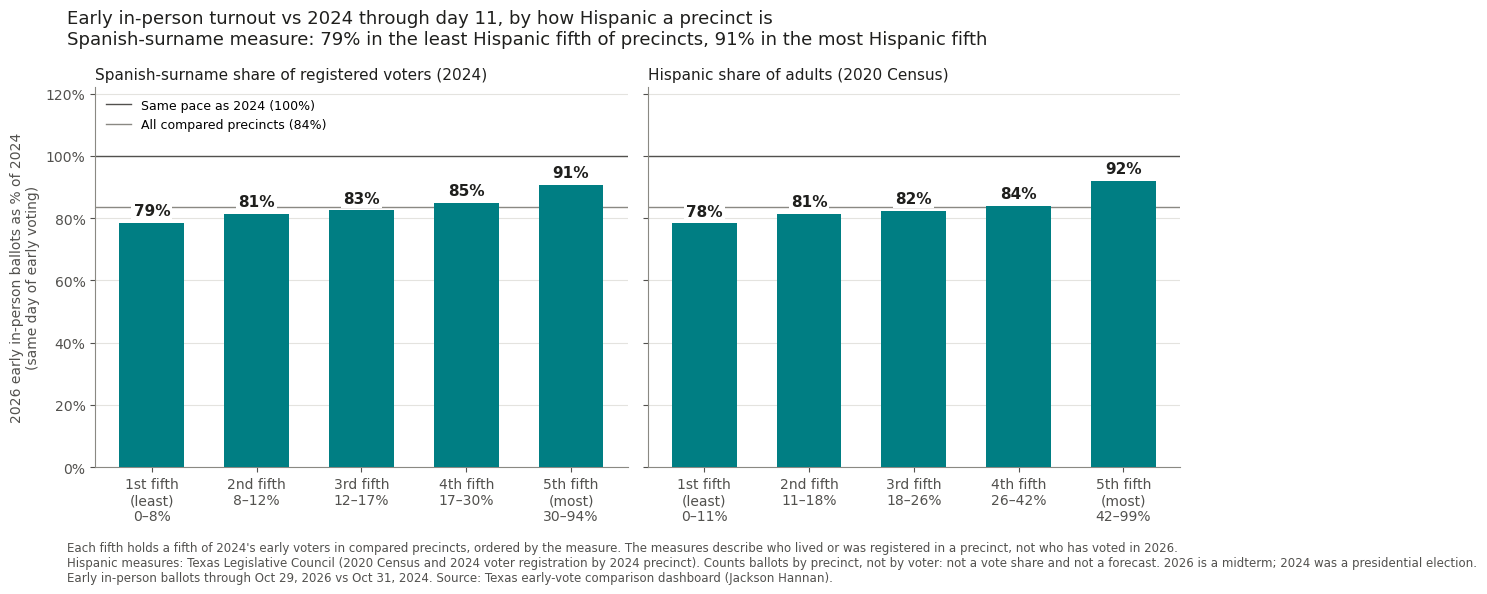

from %  to %  \
measure                                           fifth                 
Spanish-surname share of registered voters (2024) 1         0.0   7.5   
                                                  2         7.5  11.7   
                                                  3        11.7  16.8   
                                                  4        16.8  29.9   
                                                  5        29.9  93.7   
Hispanic share of adults (2020 Census)            1         0.0  11.4   
                                                  2        11.4  17.7   
                                                  3        17.7  25.8   
                                                  4        25.8  42.4   
                                                  5        42.5  99.0   

                                                         precinct groups  \
measure                                           fifth                    
Spanish-surname share of registered voters (2024) 1                 1099   
                                                  2                  877   
                                                  3                  782   
                                                  4                 1013   
                                                  5                 1807   
Hispanic share of adults (2020 Census)            1                 1076   
                                                  2                  852   
                                                  3                  810   
                                                  4                 1016   
                                                  5                 1824   

                                                         2026 as % of 2024  
measure                                           fifth                     
Spanish-surname share of registered voters (2024) 1                   78.6  
                                                  2                   81.3  
                                                  3                   82.5  
                                                  4                   85.0  
                                                  5                   90.8  
Hispanic share of adults (2020 Census)            1                   78.3  
                                                  2                   81.4  
                                                  3                   82.4  
                                                  4                   84.0  
                                                  5                   92.1

In [10]:
from matplotlib.lines import Line2D

# The Spanish-surname measure comes first: it describes registered voters, the closer of the
# two to the people who can vote.
ETHNIC_MEASURES = {
    "spanish_surname_registered_pct": "Spanish-surname share of registered voters (2024)",
    "hispanic_adult_pct": "Hispanic share of adults (2020 Census)",
}


def fifths_by(frame, column):
    """Fifths of 2024 early voters, ordered by `column`; turnout vs 2024 in each."""
    o = (
        frame.loc[frame[column].notna()]
        .sort_values([column, "county_id", "comparison_group_id"])
        .reset_index(drop=True)
    )
    weight = o.ev_2024 / o.ev_2024.sum()
    midpoint = weight.cumsum() - weight / 2
    o["fifth"] = np.minimum((midpoint * 5).astype(int), 4) + 1
    g = o.groupby("fifth").agg(
        low=(column, "min"),
        high=(column, "max"),
        groups=(column, "size"),
        ev_2024=("ev_2024", "sum"),
        ev_2026=("ev_2026", "sum"),
    )
    g["turnout_vs_2024_pct"] = 100 * g.ev_2026 / g.ev_2024
    return g


ethnic_fifths = {}
if ethnic is None:
    print("Chart 3 is not drawn because Step 5 was skipped (see the message above).")
else:
    ethnic_fifths = {column: fifths_by(ethnic, column) for column in ETHNIC_MEASURES}
    y_top = 1.22 * max(
        100, max(g.turnout_vs_2024_pct.max() for g in ethnic_fifths.values())
    )
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
    fifth_names = [
        "1st fifth\n(least)",
        "2nd fifth",
        "3rd fifth",
        "4th fifth",
        "5th fifth\n(most)",
    ]
    for ax, (column, label) in zip(axes, ETHNIC_MEASURES.items()):
        g = ethnic_fifths[column]
        positions = np.arange(len(g))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.bar(positions, g.turnout_vs_2024_pct, width=0.62, color=ACCENT, zorder=3)
        ax.axhline(100, color=INK_2, lw=1, zorder=2)
        ax.axhline(overall_pct, color=MUTED, lw=1, zorder=2)
        for i, value in enumerate(g.turnout_vs_2024_pct):
            ax.text(
                i,
                value + 1.5,
                f"{value:.0f}%",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold",
                color=INK,
                zorder=5,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
            )
        ax.set_xticks(
            positions,
            [
                f"{name}\n{row.low:.0f}–{row.high:.0f}%"
                for name, row in zip(fifth_names, g.itertuples())
            ],
        )
        ax.set_title(label, fontsize=11, color=INK, loc="left")
        ax.set_ylim(0, y_top)
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    axes[0].set_ylabel(
        "2026 early in-person ballots as % of 2024\n(same day of early voting)"
    )
    axes[0].legend(
        handles=[
            Line2D([], [], color=INK_2, lw=1, label="Same pace as 2024 (100%)"),
            Line2D(
                [],
                [],
                color=MUTED,
                lw=1,
                label=f"All compared precincts ({overall_pct:.0f}%)",
            ),
        ],
        loc="upper left",
        frameon=False,
        fontsize=9,
    )
    surname = ethnic_fifths["spanish_surname_registered_pct"].turnout_vs_2024_pct
    fig.suptitle(
        f"Early in-person turnout vs 2024 through day {day}, by how Hispanic a precinct is\n"
        f"Spanish-surname measure: {surname.iloc[0]:.0f}% in the least Hispanic fifth of "
        f"precincts, {surname.iloc[-1]:.0f}% in the most Hispanic fifth",
        x=0.06,
        ha="left",
        fontsize=13,
        color=INK,
    )
    fig.tight_layout()
    fig.text(
        0.06,
        -0.005,
        "Each fifth holds a fifth of 2024's early voters in compared precincts, ordered by the "
        "measure. The measures describe who lived or was registered in a precinct, not who "
        "has voted in 2026.\nHispanic measures: Texas Legislative Council (2020 Census and "
        "2024 voter registration by 2024 precinct). " + CAVEAT + "\n" + SOURCE,
        fontsize=8.5,
        color=INK_2,
        ha="left",
        va="top",
    )
    fig.savefig(
        OUTPUT_DIRECTORY / "chart3_turnout_by_hispanic_share.png",
        dpi=200,
        bbox_inches="tight",
    )
    fig.savefig(
        OUTPUT_DIRECTORY / "chart3_turnout_by_hispanic_share.svg", bbox_inches="tight"
    )
    plt.show()
    display(
        pd.concat(
            {
                label: ethnic_fifths[column][
                    ["low", "high", "groups", "turnout_vs_2024_pct"]
                ]
                for column, label in ETHNIC_MEASURES.items()
            },
            names=["measure", "fifth"],
        )
        .rename(
            columns={
                "low": "from %",
                "high": "to %",
                "groups": f"{UNIT}s",
                "turnout_vs_2024_pct": "2026 as % of 2024",
            }
        )
        .round(1)
    )

### Holding the 2024 vote fixed

The cross-table compares precincts that voted similarly in 2024 but differ in how Hispanic their registered voters are. Read across a row: if turnout vs 2024 rises from left to right within the same 2024 vote band, the Hispanic pattern is not just the partisan pattern again. Cells with fewer than 20,000 2024 early ballots are left blank.

The model fits turnout vs 2024 on 2024 Harris share and a Hispanic measure together, weighted and with county-clustered ranges as in Step 4. It reports each one's slope with the other held fixed.

In [11]:
ethnic_cross = ethnic_models = None
if ethnic is None:
    print("Nothing to show here because Step 5 was skipped (see the message above).")
else:
    cross = ethnic.dropna(subset=["spanish_surname_registered_pct"]).copy()
    cross["2024 Harris share"] = pd.cut(
        cross[X],
        [0, 40, 50, 60, 100.001],
        right=False,
        labels=["under 40%", "40–50%", "50–60%", "60% or more"],
    )
    cross["Spanish-surname share of registered voters"] = pd.cut(
        cross.spanish_surname_registered_pct,
        [0, 20, 50, 80, 100.001],
        right=False,
        labels=["under 20%", "20–50%", "50–80%", "80% or more"],
    )
    cells = cross.groupby(
        ["2024 Harris share", "Spanish-surname share of registered voters"],
        observed=False,
    )[["ev_2024", "ev_2026"]].sum()
    ethnic_cross = (
        (100 * cells.ev_2026 / cells.ev_2024).where(cells.ev_2024 >= 20_000).unstack()
    )
    print(
        "2026 early in-person ballots as % of 2024, by 2024 vote (rows) and Hispanic share (columns):"
    )
    display(ethnic_cross.round(1))
    print("2024 early in-person ballots in each cell, thousands:")
    display((cells.ev_2024 / 1000).unstack().round(0))

    model_rows = []
    for column, label in ETHNIC_MEASURES.items():
        frame = ethnic.dropna(subset=[column])
        for county_effects in (False, True):
            formula = f"{Y} ~ {X} + {column}" + (
                " + C(county_id)" if county_effects else ""
            )
            result = smf.wls(formula, data=frame, weights=frame.ev_2024).fit(
                cov_type="cluster", cov_kwds={"groups": frame.county_id}, use_t=True
            )
            low, high = result.conf_int().loc[column]
            model_rows.append(
                {
                    "Hispanic measure": label,
                    "comparison": "within the same county"
                    if county_effects
                    else "all compared precincts",
                    "per +10 pts Hispanic measure": 10 * result.params[column],
                    "range_low": 10 * low,
                    "range_high": 10 * high,
                    "per +10 pts 2024 Harris share": 10 * result.params[X],
                    f"{UNIT}s": int(result.nobs),
                }
            )
    ethnic_models = pd.DataFrame(model_rows)
    display(
        ethnic_models.rename(
            columns={
                "comparison": "Comparison",
                "range_low": "95% range, low",
                "range_high": "95% range, high",
            }
        ).round(2)
    )
    main = ethnic_models.loc[
        (
            ethnic_models["Hispanic measure"]
            == ETHNIC_MEASURES["spanish_surname_registered_pct"]
        )
        & (ethnic_models.comparison == "all compared precincts")
    ].iloc[0]
    print(
        f"Reading: holding 2024 Harris share fixed, each +10 points of Spanish-surname share of "
        f"registered voters goes with {main['per +10 pts Hispanic measure']:+.1f} points of "
        f"turnout vs 2024 (95% range {main.range_low:+.1f} to {main.range_high:+.1f}). "
        f"Holding that fixed, each +10 points of 2024 Harris share goes with "
        f"{main['per +10 pts 2024 Harris share']:+.1f} points."
    )

2026 early in-person ballots as % of 2024, by 2024 vote (rows) and Hispanic share (columns):


Spanish-surname share of registered voters,under 20%,20–50%,50–80%,80% or more
2024 Harris share,,,,
under 40%,76.5,75.1,78.5,NaN
40–50%,84.4,84.9,93.8,106.0
50–60%,86.7,89.2,92.3,103.6
60% or more,91.1,96.0,94.6,95.1


2024 early in-person ballots in each cell, thousands:


Spanish-surname share of registered voters,under 20%,20–50%,50–80%,80% or more
2024 Harris share,,,,
under 40%,2128.0,385.0,57.0,1.0
40–50%,686.0,236.0,91.0,59.0
50–60%,473.0,350.0,141.0,61.0
60% or more,570.0,316.0,104.0,51.0


,Hispanic measure,Comparison,per +10 pts Hispanic measure,"95% range, low","95% range, high",per +10 pts 2024 Harris share,precinct groups
0,Spanish-surname share of registered voters (2024),all compared precincts,1.36,0.34,2.39,3.49,5578
1,Spanish-surname share of registered voters (2024),within the same county,2.29,1.22,3.36,2.71,5578
2,Hispanic share of adults (2020 Census),all compared precincts,1.28,0.41,2.14,3.37,5578
3,Hispanic share of adults (2020 Census),within the same county,1.98,1.30,2.65,2.56,5578


Reading: holding 2024 Harris share fixed, each +10 points of Spanish-surname share of registered voters goes with +1.4 points of
 turnout vs 2024 (95% range +0.3 to +2.4). Holding that fixed, each +10 points of 2024 Harris share goes with +3.5 points.


## Explore the data yourself

The two tables below are the data behind every chart, in plain columns. In nteract they are interactive: the bars above each column show its distribution, and the table tools let you sort, filter and chart the columns. A static viewer such as GitHub shows only the first rows.

- **Precincts:** one row per compared precinct or merged precinct group. It includes its 2024 vote, early ballots in both years, turnout vs 2024, which fifth of 2024 early voters it falls in (Charts 1 and 2), and the Step 5 Hispanic measures.
- **Counties:** the same figures rolled up by county, with how much of each county's 2024 vote is compared and how the rest of the county voted.

Turnout vs 2024 is always summed 2026 ballots ÷ summed 2024 ballots. Running the notebook also saves both tables as CSV files (see the last section).

In [12]:
base = (
    ethnic
    if ethnic is not None
    else sample.assign(
        hispanic_adult_pct=np.nan,
        spanish_surname_registered_pct=np.nan,
        registered_2024=np.nan,
    )
)
fifth_of = (
    ordered_by_voters.assign(
        fifth=np.minimum((ordered_by_voters.x_mid // 20).astype(int), 4) + 1
    )
    .set_index(["county_id", "comparison_group_id"])
    .fifth
)
base = base.join(fifth_of, on=["county_id", "comparison_group_id"])

precinct_table = (
    pd.DataFrame(
        {
            "County": base.county,
            "2024 precincts": base.precinct_ids_2024.map(", ".join),
            "2026 precincts": base.precinct_ids_2026.map(", ".join),
            "Same lines both years": base.unchanged_precinct,
            "2024 winner": np.select(
                [base[X] > 50, base[X] < 50], ["Harris", "Trump"], default="Tie"
            ),
            "2024 Harris share %": base[X].round(1),
            "Fifth of 2024 early voters (1 = most Trump)": base.fifth.astype("Int64"),
            "2024 early ballots": base.ev_2024.astype("Int64"),
            "2026 early ballots": base.ev_2026.astype("Int64"),
            "2026 as % of 2024": (100 * base.ev_2026 / base.ev_2024).round(1),
            "2024 Harris + Trump votes": base.voters_2024_two_party.astype("Int64"),
            "2024 registered voters": base.registered_2024.round(0).astype("Int64"),
            "Hispanic share of adults %": base.hispanic_adult_pct.round(1),
            "Spanish-surname share of registered voters %": base.spanish_surname_registered_pct.round(
                1
            ),
            "2024 results source": np.where(
                base.presidential_reference_type == "tlc_retabulated",
                "Texas Legislative Council",
                "County canvass",
            ),
        }
    )
    .assign(
        _order=base.precinct_ids_2024.map(
            lambda ids: (int(re.match(r"\d*", ids[0]).group() or 0), ids[0])
        )
    )
    .sort_values(["County", "_order"])
    .drop(columns="_order")
    .reset_index(drop=True)
)


def county_rollup(frame):
    def share(numerator, denominator):
        return 100 * frame[numerator].sum() / frame[denominator].sum()

    with_reg = frame.dropna(
        subset=["spanish_surname_registered_pct", "registered_2024"]
    )
    return pd.Series(
        {
            f"Compared {UNIT}s": len(frame),
            "2024 early ballots": int(frame.ev_2024.sum()),
            "2026 early ballots": int(frame.ev_2026.sum()),
            "2026 as % of 2024": round(share("ev_2026", "ev_2024"), 1),
            "2024 Harris share % in compared precincts": round(
                share("harris_votes_2024", "voters_2024_two_party"), 1
            ),
            "Spanish-surname share of registered voters %": round(
                (
                    with_reg.spanish_surname_registered_pct * with_reg.registered_2024
                ).sum()
                / with_reg.registered_2024.sum(),
                1,
            )
            if len(with_reg)
            else np.nan,
        }
    )


county_table = (
    base.assign(harris_votes_2024=base.harris_votes_2024.astype(float))
    .groupby("county")
    .apply(county_rollup, include_groups=False)
    .reset_index()
    .rename(columns={"county": "County"})
    .sort_values("2024 early ballots", ascending=False)
    .reset_index(drop=True)
    .astype(
        {
            f"Compared {UNIT}s": "Int64",
            "2024 early ballots": "Int64",
            "2026 early ballots": "Int64",
        }
    )
)
county_keys = county_table.County.map(county_name_key)
county_table["Share of county's 2024 vote compared %"] = county_keys.map(
    coverage["compared %"]
).round(1)
county_table["2024 Harris share % in the rest of the county"] = county_keys.map(
    coverage["Harris % in the rest of the county"]
).round(1)
print(f"Precincts: {len(precinct_table):,} rows. Counties: {len(county_table)} rows.")
display(precinct_table)
display(county_table)

Precincts: 5,589 rows. Counties: 213 rows.


,County,2024 precincts,2026 precincts,Same lines both years,2024 winner,2024 Harris share %,Fifth of 2024 early voters (1 = most Trump),2024 early ballots,2026 early ballots,2026 as % of 2024,2024 Harris + Trump votes,2024 registered voters,Hispanic share of adults %,Spanish-surname share of registered voters %,2024 results source
0,Anderson,1,1,True,Trump,29.5,2,745,581,78.0,1101,1870,12.1,11.1,Texas Legislative Council
1,Anderson,2,2,True,Trump,9.8,1,1172,799,68.2,1864,2850,6.0,4.2,Texas Legislative Council
2,Anderson,3,3,True,Trump,12.9,1,643,466,72.5,854,1268,10.8,6.2,Texas Legislative Council
3,Anderson,4,4,True,Trump,9.3,1,748,512,68.4,1176,1715,4.5,4.0,Texas Legislative Council
4,Anderson,6,6,True,Trump,44.2,3,497,418,84.1,769,1520,21.0,9.9,Texas Legislative Council
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5584,Zapata,1,1,True,Trump,42.6,3,710,416,58.6,1135,1881,94.2,89.0,Texas Legislative Council
5585,Zapata,2,2,True,Trump,35.6,2,543,412,75.9,939,1579,92.7,89.0,Texas Legislative Council
5586,Zapata,2A,2A,True,Trump,42.3,3,171,131,76.6,355,577,93.8,89.9,Texas Legislative Council
5587,Zapata,3,3,True,Trump,33.4,2,972,540,55.6,1453,2303,84.9,79.4,Texas Legislative Council


,County,Compared precinct groups,2024 early ballots,2026 early ballots,2026 as % of 2024,2024 Harris share % in compared precincts,Spanish-surname share of registered voters %,Share of county's 2024 vote compared %,2024 Harris share % in the rest of the county
0,Harris,954,1047862,909842,86.8,52.8,24.7,100.0,NaN
1,Bexar,541,424142,370800,87.4,55.4,46.3,82.5,52.8
2,Travis,222,375076,343170,91.5,69.9,15.7,90.4,71.2
3,Collin,217,369396,302422,81.9,44.1,8.4,96.6,49.6
4,Denton,195,323537,273248,84.5,43.6,10.5,97.1,34.1
...,...,...,...,...,...,...,...,...,...
208,Roberts,2,140,96,68.6,3.2,4.3,38.3,3.7
209,Sterling,1,123,79,64.2,5.0,17.6,28.8,7.6
210,Foard,1,121,66,54.5,15.2,9.2,31.7,17.9
211,Briscoe,1,120,95,79.2,8.1,17.9,25.1,10.3


## What this does and doesn't show

- **Precincts, not people.** The pattern is about places. It does not say which voters are turning out, or how they will vote. Steps 1–5 and Appendices A–B are not a vote share and not a forecast. Appendix C is the one place that estimates a statewide result, and it does so only under the assumptions written out there.
- **Midterm vs presidential.** 2026 is a midterm and 2024 was a presidential election, so fewer ballots overall is normal. The comparison that matters is between kinds of precincts.
- **A moving number.** The embedded snapshot runs through day 11 of the 12 days of early voting, and Election Day is not included. The latest days can include partial or missing county reports. In this snapshot the dashboard could not read Dallas County's latest 2026 reports, so Dallas, a large Harris-leaning county, is in the comparison through day 9 but not on days 10 and 11. Set `EARLY_VOTING_DAY = 9` to see the comparison with Dallas included. Among precincts reported on every day, the gap between the most Trump-voting and most Harris-voting fifths was about 22 points on day 1 and about 21 on day 11 (Appendix B).
- **The 2024 baseline has its own habits.** In 2024, Trump-won precincts cast a larger share of their total vote early in person than Harris-won precincts did (Appendix A prints both figures). So part of the gap reflects how 2024 voters timed their vote. Appendix A also measures the pattern against all 2024 Harris + Trump voters instead.
- **Coverage.** Not every precinct is compared, and which ones are can change from day to day as counties report. Step 1 prints how the compared precincts voted in 2024 next to the rest of Texas (in this snapshot, about 43% Harris in each). The overall figures describe the compared precincts, not the whole state. Within partly covered counties, the compared part sometimes voted differently from the rest in 2024; Step 1 and the county table in the Explore section show where.
- **Hispanic share describes places too.** Step 5's measures describe who lived in a precinct in 2020 or who was registered there in 2024, not who has voted in 2026. Surname counts miss some Hispanic voters and include some who are not Hispanic.
- **Boundaries.** November 2026 precinct lines are approximated by the 2026 primary lines. Step 5's tables use the 2024 precinct lines, the same as the 2024 results; the Texas Legislative Council sometimes splits a precinct into lettered parts, which are added back together.

## Appendix A: Does the result depend on choices made above?

Each row changes one choice and re-measures the pattern. Rows in "points per +10 Harris pts" use the same units as Step 4. The last three rows are in "% change per +10 Harris pts", which puts different baselines on a common scale.

In [13]:
rows = []


def add_row(check, fit, units="points per +10 Harris pts", what=""):
    rows.append(
        {
            "check": check,
            "estimate": fit["slope_per_10_pts"],
            "range_low": fit["range_low"],
            "range_high": fit["range_high"],
            "units": units,
            "what it tests": what,
        }
    )


def relative_fit(frame, outcome, weight_column, denominator):
    """Slope rescaled to % of the average level, so different baselines compare."""
    result = smf.wls(f"{outcome} ~ {X}", data=frame, weights=frame[weight_column]).fit(
        cov_type="cluster", cov_kwds={"groups": frame.county_id}, use_t=True
    )
    mean = 100 * frame.ev_2026.sum() / frame[denominator].sum()
    low, high = result.conf_int().loc[X]
    return {
        "slope_per_10_pts": 1000 * result.params[X] / mean,
        "range_low": 1000 * low / mean,
        "range_high": 1000 * high / mean,
    }


screen_note = "after the data-quality screen" if APPLY_QC else "data-quality screen off"
add_row("Main result", main_fit, what=f"Weighted by 2024 early voters, {screen_note}")
add_row("Within the same county", county_fit, what="Removes county-wide differences")
add_row(
    "Equal weight per precinct",
    fit_line(sample, None),
    what="Small precincts count as much as large ones",
)
add_row(
    "Weighted by 2024 Harris + Trump voters",
    fit_line(sample, "voters_2024_two_party"),
    what="Size by full 2024 electorate instead of early voters",
)
if COHORT == "matched":
    add_row(
        "Unchanged precincts only",
        fit_line(sample.loc[sample.unchanged_precinct]),
        what="Drops merged precinct groups",
    )
if APPLY_QC:
    add_row(
        "No data-quality screen",
        fit_line(eligible.loc[eligible.ev_2024 >= 1]),
        what="Keeps the flagged groups",
    )

alt = sample.assign(
    ev_2026_per_100_2024_voters=100 * sample.ev_2026 / sample.voters_2024_two_party
)
add_row(
    "Baseline = 2024 early ballots (main)",
    relative_fit(alt, Y, "ev_2024", "ev_2024"),
    "% change per +10 Harris pts",
    "Main result, rescaled to % of the average",
)
add_row(
    "Baseline = all 2024 Harris + Trump voters",
    relative_fit(
        alt,
        "ev_2026_per_100_2024_voters",
        "voters_2024_two_party",
        "voters_2024_two_party",
    ),
    "% change per +10 Harris pts",
    "Removes differences in how 2024 voters timed their vote",
)
counts_model = smf.glm(
    f"ev_2026 ~ {X}",
    data=sample,
    family=sm.families.Poisson(),
    offset=np.log(sample.ev_2024),
).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(sample.county_id)[0]})
low, high = counts_model.conf_int().loc[X]


def to_pct(b):
    return 100 * (np.exp(10 * b) - 1)


add_row(
    "Count model (Poisson, 2024 ballots as exposure)",
    {
        "slope_per_10_pts": to_pct(counts_model.params[X]),
        "range_low": to_pct(low),
        "range_high": to_pct(high),
    },
    "% change per +10 Harris pts",
    "Multiplicative instead of straight-line",
)
robustness = pd.DataFrame(rows)
display(
    robustness.rename(
        columns={
            "check": "Check",
            "estimate": "Estimate",
            "range_low": "95% range, low",
            "range_high": "95% range, high",
            "units": "Units",
            "what it tests": "What it tests",
        }
    ).round(2)
)


def early_share_2024(mask):
    return (
        100
        * sample.loc[mask, "ev_2024"].sum()
        / sample.loc[mask, "voters_2024_two_party"].sum()
    )


print(
    f"How 2024 voters timed their vote: by day {day} of 2024, Trump-won precincts had cast "
    f"early in-person ballots equal to {early_share_2024(trump_won):.1f}% of their final "
    f"2024 Harris + Trump vote; Harris-won precincts {early_share_2024(harris_won):.1f}%."
)

,Check,Estimate,"95% range, low","95% range, high",Units,What it tests
0,Main result,3.90,3.45,4.35,points per +10 Harris pts,"Weighted by 2024 early voters, after the data-..."
1,Within the same county,3.28,2.87,3.69,points per +10 Harris pts,Removes county-wide differences
2,Equal weight per precinct,4.24,3.66,4.81,points per +10 Harris pts,Small precincts count as much as large ones
3,Weighted by 2024 Harris + Trump voters,3.98,3.51,4.45,points per +10 Harris pts,Size by full 2024 electorate instead of early ...
4,Unchanged precincts only,3.88,3.46,4.30,points per +10 Harris pts,Drops merged precinct groups
5,No data-quality screen,3.87,3.41,4.34,points per +10 Harris pts,Keeps the flagged groups
6,Baseline = 2024 early ballots (main),4.66,4.12,5.20,% change per +10 Harris pts,"Main result, rescaled to % of the average"
7,Baseline = all 2024 Harris + Trump voters,3.73,2.64,4.82,% change per +10 Harris pts,Removes differences in how 2024 voters timed t...
8,"Count model (Poisson, 2024 ballots as exposure)",4.73,4.14,5.33,% change per +10 Harris pts,Multiplicative instead of straight-line


How 2024 voters timed their vote: by day 11 of 2024, Trump-won precincts had cast early in-person ballots equal to 71.5% of thei
r final 2024 Harris + Trump vote; Harris-won precincts 67.9%.


## Appendix B: How the gap has moved day by day

Only precinct groups reported on every day are used, so changes from day to day are not caused by precincts entering or leaving the comparison. The latest day can still include partial county reports. Each figure is that fifth's early ballots so far as a % of 2024 through the same day.

In [14]:
history = published.loc[
    (published.early_voting_day <= day)
    & (published.ev_2024.fillna(0) > 0)
    & published.ev_2026.notna()
].copy()
history[["ev_2024", "ev_2026"]] = history[["ev_2024", "ev_2026"]].astype(float)
# Fifths of 2024 early voters, as defined on the latest day.
keys = ordered_by_voters.assign(
    fifth=np.minimum((ordered_by_voters.x_mid // 20).astype(int), 4) + 1
)[["county_id", "comparison_group_id", "fifth"]]
history = history.merge(keys, on=["county_id", "comparison_group_id"], how="inner")
days_present = history.groupby(
    ["county_id", "comparison_group_id"]
).early_voting_day.nunique()
published_days = history.early_voting_day.nunique()  # normally every day 1 to `day`
complete = days_present[days_present == published_days].index
history = (
    history.set_index(["county_id", "comparison_group_id"]).loc[complete].reset_index()
)

by_day = history.groupby(["early_voting_day", "fifth"])[["ev_2024", "ev_2026"]].sum()
by_day = (100 * by_day.ev_2026 / by_day.ev_2024).unstack("fifth")
by_day.columns = [f"fifth {c}" for c in by_day.columns]
totals = history.groupby("early_voting_day")[["ev_2024", "ev_2026"]].sum()
by_day["all"] = 100 * totals.ev_2026 / totals.ev_2024
by_day["gap: fifth 5 − fifth 1"] = by_day["fifth 5"] - by_day["fifth 1"]
by_day = by_day.rename_axis("early-voting day")
n_groups = history.groupby(["county_id", "comparison_group_id"]).ngroups
gap = by_day["gap: fifth 5 − fifth 1"]
print(
    f"{n_groups:,} {UNIT}s reported on all {published_days} published days through "
    f"day {day}. Gap between the most "
    f"Harris-voting and most Trump-voting fifths: {gap.iloc[0]:.1f} points on day "
    f"{gap.index[0]}, {gap.iloc[-1]:.1f} on day {gap.index[-1]}."
)
display(by_day.round(1))

5,580 precinct groups reported on all 11 published days through day 11. Gap between the most Harris-voting and most Trump-voting
 fifths: 21.7 points on day 1, 21.2 on day 11.


,fifth 1,fifth 2,fifth 3,fifth 4,fifth 5,all,gap: fifth 5 − fifth 1
early-voting day,,,,,,,
1,70.7,76.5,82.1,88.2,92.4,81.6,21.7
2,71.6,77.0,82.9,89.3,94.0,82.5,22.4
3,71.3,76.4,82.8,88.9,94.0,82.3,22.8
4,70.6,76.1,82.6,88.4,93.3,81.8,22.7
5,70.3,76.3,82.6,88.2,92.9,81.7,22.6
6,69.4,76.8,83.5,88.7,92.8,82.0,23.4
7,69.1,77.1,84.0,88.9,93.0,82.2,23.8
8,68.8,77.0,83.9,88.5,92.4,81.9,23.6
9,69.2,77.2,84.0,88.1,91.9,81.9,22.7


## Appendix C: The projection, and a reference scenario

Everything above describes turnout. This appendix asks a different question: **what statewide result does the turnout pattern point to, and how often would each party win?** Turnout counts cannot show how anyone voted, so vote choice has to come from somewhere. The two models below get it in different ways. They are alternatives; never add one to the other.

- **The projection, vote choice from the polls.** The result is anchored on each race's polling average, with a polling error. The early-vote data, the independent vote and the third-party candidates split the poll-implied change into its parts.
- **The reference scenario, people vote as they did in 2024.** Every precinct votes the way it did in 2024, give or take the usual change between elections. Only the early-vote turnout pattern moves the result, which shows what turnout alone would do. It comes first because the projection uses its turnout estimate.

**One accounting identity, with no overlap between its terms.**

Democratic share of the 2026 two-party vote = 2024 share (43.06%) + **G** + **I** + **T** + **R**

| Term | What it contains | What it does not contain | Where it comes from |
|---|---|---|---|
| **G**: where people vote | The change that comes from some precincts turning out more than others compared with 2024, if each precinct votes as it did in 2024 | Any change in how people vote, or in who votes inside a precinct | The early-vote data (Steps 1–4) |
| **I**: how independents vote | The change in independents' two-party vote since 2024, weighted by independents' 2024 share of the electorate | A larger share of independents voting. That is in G where it changes which precincts vote, and in R where it changes who votes inside a precinct | The 2024 exit poll and an October 2026 survey |
| **T**: third-party pull | How much the third-party candidates' votes beyond the 2024 third-party share come more from the Republican than from the Democrat | Any change in how the two major candidates' own voters choose between them | The polls' third-party share and an assumed 65/35 split |
| **R**: everything else | Partisans changing sides, candidate effects, who votes inside a precinct, and the small interactions between the terms (listed in full under the projection) | Anything in G, I or T, and the polling error | What is left over |

The reference scenario replaces I + T + R with a swing drawn around zero. The projection takes the total from the polls and splits it, so G + I + T + R equals the poll-implied change exactly.

**How double counting is avoided**

1. Likely-voter polls already reflect who is turning out, how independents are voting and how many people back third-party candidates. In the projection, G, I and T are therefore slices of the poll average, never additions to it. The code checks that G + I + T + R adds up to the poll-implied change.
2. The independent swing I holds independents at their 2024 share of the electorate, so extra independents are not counted in I. Where they change which precincts vote, they are already in G; where they change who votes inside a precinct, they are in R.
3. New and infrequent voters are in the polls to the extent the pollsters' likely-voter screens catch them. The only way to add anything beyond the polls is the `NEW_VOTER_LIFT` setting. It is 0 by default; raise it only for voters you believe the polls miss.
4. The 65/35 third-party split is already in the poll average, because the polls offer the Libertarian candidates as a choice. T only shows how much of the poll-implied change it accounts for. The split changes the outcome only when a third-party candidate's final share differs from its polled share: voters who drift back to a major party, or away from one, move 65% Republican and 35% Democratic. `THIRD_PARTY_GAP` sets the expected difference, and it is 0 by default.
5. Heavier turnout on the last day of early voting will enter G once the dashboard publishes it. In the projection that changes how the poll average splits, not the total, unless the polls did not expect it. In that case it belongs in `NEW_VOTER_LIFT`.

### Reference scenario: if people vote as they did in 2024

**The question:** if the turnout pattern so far holds and people vote the way they did in 2024, what statewide result follows, and how often would each party win? The answer rests on assumptions. They are listed below, and each one is a setting at the top of the next cell.

**The model in one line.** Democratic share of the 2026 two-party vote = 2024 share + turnout effect × carry-over + swing.

- **2024 share:** 43.06%, Harris's share of the statewide Harris + Trump vote (Texas Legislative Council county totals).
- **Turnout effect:** how far that share moves if every precinct votes exactly as it did in 2024 but turns out in 2026 at the rate its early in-person voting so far implies. It is measured on the compared precincts, and the rest of Texas is filled in as described below.
- **Carry-over:** how much of the turnout effect survives into the final count, which also includes the remaining early-voting days, mail ballots and Election Day.
- **Swing:** any change in how precincts vote compared with 2024, applied evenly everywhere. Early-vote counts carry no information about it.

A Monte Carlo simulation draws every uncertain piece 100,000 times and adds them up. It reports the spread of results and how often each party is above 50% of the two-party vote.

| # | Assumption | Value used | Why |
|---|---|---|---|
| 1 | The race | One generic statewide race, Democrat vs Republican. Third parties are ignored, and the winner is whoever has more than 50% of the two-party vote. | Texas elects a U.S. senator and a governor in 2026, with different candidates. In 2018 the two statewide races differed by about 5.5 points. |
| 2 | Compared precincts | Each precinct's final 2026 turnout relative to 2024 follows its early in-person turnout vs 2024 so far. | The measure used throughout this notebook. |
| 3 | Partly compared counties | The rest of the county turns out like its compared part, adjusted along the Step 4 line for its different 2024 vote. Random error: half the between-county spread in #4. | Same county election office and calendar. |
| 4 | Counties with no compared precincts (Dallas, Guadalupe and Taylor on day 11) | Turnout comes from the Step 4 line at the county's 2024 Harris share. The line's own uncertainty comes from its county-clustered fit, and a random county error with the between-county spread of turnout around the line (weighted by size; printed below). | The line fits the compared counties well. On day 9, the last day it was reported, Dallas ran a few points above it. |
| 5 | Reporting error | Each compared county's turnout ratio is off by a random 2% (standard deviation). | Latest-day county reports can be partial. |
| 6 | Early in-person share of the final vote | Uniform between 62% and 76%. The remaining early-voting days are assumed to look like the days so far. | 63.5% in the 2022 midterm and 75.8% in 2024 (U.S. Election Assistance Commission, EAVS Texas data briefs for [2022](https://www.eac.gov/sites/default/files/2023-10/2022_EAVS_Data_Brief_TX_508c.pdf) and [2024](https://www.eac.gov/sites/default/files/2026-07/2024_EAVS_Data_Brief_TX.pdf)). |
| 7 | Mail and Election Day voters | They repeat a share of the early-vote turnout gap drawn from a normal distribution with mean 0.5 and SD 0.5. 1 means the same gap, 0 no gap, and below 0 means they offset it. | No direct evidence. The gap between fifths narrowed slightly during early voting (Appendix B), which hints that later voters differ less. |
| 8 | Swing in how precincts vote | Normal, mean 0, SD 3.5 points, the same everywhere. | Mean 0: precincts vote as they did in 2024, the baseline assumption of this notebook. SD 3.5: the spread of past presidential-to-midterm changes in Texas's top statewide races (table below). |
| 9 | Independence | The pieces above are drawn independently of each other. | The simplest choice. |

**Not modeled:** precincts swinging by different amounts (for example, heavily Hispanic precincts moving differently from 2024), any link between who turns out and how they vote, new registrants, candidate quality and polling. Public polls measure vote choice directly, and the projection uses them. In late October 2026 they put both races far closer than this scenario does. The whole difference sits in the swing term, which turnout data cannot see. The sensitivity tables below and the right panel of Chart 4 show the results under other swing assumptions.

**Past presidential-to-midterm changes in Texas** (Democratic share of the two-party vote, from Texas Secretary of State results):

| Presidential year | Democratic two-party share | Next midterm, top statewide races | Democratic two-party share | Change, points |
|---|---|---|---|---|
| 2012 | 42.0% | 2014 governor / U.S. Senate | 39.6% / 35.8% | −2.4 / −6.2 |
| 2016 | 45.3% | 2018 U.S. Senate / governor | 48.7% / 43.2% | +3.4 / −2.1 |
| 2020 | 47.2% | 2022 governor | 44.5% | −2.7 |

These changes mix turnout and vote choice. Three of the five came in midterms under a Democratic president, and the one midterm under a Republican president (2018) split by race. So the model centers the swing at 0 rather than at their average (−2.0) and borrows only their spread (SD 3.4).

**How to read the result.** The turnout effect is measured from the data. The swing is an assumption, and it largely decides the win probabilities. Read them as what the turnout pattern implies if vote choice looks like 2024, give or take the usual cycle-to-cycle change. They are not a forecast.

In [15]:
# --- Assumptions (numbered as in the table above) ---------------------------------------
SCENARIO_SEED = 2026  # fixed, so the results reproduce exactly
SCENARIO_DRAWS = 100_000
# 5: random error in a compared county's turnout ratio, in %
COUNTY_REPORTING_SD_PCT = 2.0
# 6: uniform range for the early in-person share of the final vote
EARLY_IN_PERSON_SHARE = (0.62, 0.76)
# 7: mean and SD of the share of the early-vote gap that later voters repeat
REST_REPEATS_GAP = (0.5, 0.5)
# 8: mean and SD of the uniform swing in vote choice, points toward Democrats
SWING_VS_2024 = (0.0, 3.5)

rng = np.random.default_rng(SCENARIO_SEED)

# County building blocks: compared precincts (their own turnout ratios) and the rest.
precincts = sample.assign(
    key=sample.county.map(county_name_key),
    harris=sample.harris_votes_2024.astype(float),
    ratio=sample.ev_2026 / sample.ev_2024,
)
compared_sums = (
    precincts.assign(
        ratio_harris=precincts.ratio * precincts.harris,
        ratio_votes=precincts.ratio * precincts.voters_2024_two_party,
        share_x_ev=precincts.ev_2024 * precincts[X],
    )
    .groupby("key")[
        [
            "ratio_harris",
            "ratio_votes",
            "harris",
            "voters_2024_two_party",
            "ev_2024",
            "ev_2026",
            "share_x_ev",
        ]
    ]
    .sum()
)
blocks = (
    county_totals[["county", "harris", "two_party"]]
    .join(compared_sums, rsuffix="_compared")
    .fillna(0)
)
is_compared = (blocks.voters_2024_two_party > 0).to_numpy()
rest_votes = (blocks.two_party - blocks.voters_2024_two_party).clip(lower=0)
rest_harris = np.minimum(
    (blocks.harris - blocks.harris_compared).clip(lower=0), rest_votes
)
county_ratio_pct = 100 * blocks.ev_2026 / blocks.ev_2024.where(blocks.ev_2024 > 0)
county_share_pct = blocks.share_x_ev / blocks.ev_2024.where(blocks.ev_2024 > 0)
baseline = (blocks.harris_compared.sum() + rest_harris.sum()) / (
    blocks.voters_2024_two_party.sum() + rest_votes.sum()
)

# The Step 4 line, its uncertainty, and how far whole counties sit from it.
line = smf.wls(f"{Y} ~ {X}", data=sample, weights=sample.ev_2024).fit(
    cov_type="cluster", cov_kwds={"groups": sample.county_id}, use_t=True
)
residual = (
    county_ratio_pct - line.params["Intercept"] - line.params[X] * county_share_pct
)[is_compared]
size = blocks.voters_2024_two_party[is_compared]
between_county_sd = float(np.sqrt((size * residual**2).sum() / size.sum()))

has_rest = (rest_votes > 0).to_numpy()
rest_h = (100 * rest_harris / rest_votes.where(rest_votes > 0)).to_numpy()[has_rest]
rest_v, rest_hv = rest_votes.to_numpy()[has_rest], rest_harris.to_numpy()[has_rest]
partly = is_compared[has_rest]
own_ratio, own_share = (
    county_ratio_pct.to_numpy()[has_rest],
    county_share_pct.to_numpy()[has_rest],
)
error_sd = np.where(partly, between_county_sd / 2, between_county_sd)
compared_a = blocks.ratio_harris.to_numpy()[is_compared]
compared_b = blocks.ratio_votes.to_numpy()[is_compared]

# Turnout effect: the move in the statewide share if precincts vote exactly as in 2024.
turnout_effect = np.empty(SCENARIO_DRAWS)
for start in range(0, SCENARIO_DRAWS, 10_000):
    n = min(10_000, SCENARIO_DRAWS - start)
    coef = rng.multivariate_normal(
        line.params.to_numpy(), line.cov_params().to_numpy(), n
    )
    reporting = 1 + rng.normal(0, COUNTY_REPORTING_SD_PCT / 100, (n, len(compared_a)))
    from_line = coef[:, [0]] + coef[:, [1]] * rest_h
    from_own_county = own_ratio + coef[:, [1]] * (rest_h - own_share)
    predicted = np.where(partly, from_own_county, from_line) + error_sd * rng.normal(
        size=(n, len(rest_h))
    )
    predicted = np.clip(predicted, 30, 200) / 100
    harris_weighted = reporting @ compared_a + predicted @ rest_hv
    all_weighted = reporting @ compared_b + predicted @ rest_v
    turnout_effect[start : start + n] = 100 * (
        harris_weighted / all_weighted - baseline
    )

early_share = rng.uniform(*EARLY_IN_PERSON_SHARE, SCENARIO_DRAWS)
repeat_z = rng.normal(size=SCENARIO_DRAWS)
swing_z = rng.normal(size=SCENARIO_DRAWS)


def carry_over(repeat_mean=REST_REPEATS_GAP[0], repeat_sd=REST_REPEATS_GAP[1]):
    return early_share + (1 - early_share) * (repeat_mean + repeat_sd * repeat_z)


def dem_share(swing_mean=SWING_VS_2024[0], swing_sd=SWING_VS_2024[1], **carry):
    """Simulated Democratic share of the two-party vote, in %."""
    return (
        100 * baseline
        + carry_over(**carry) * turnout_effect
        + swing_mean
        + swing_sd * swing_z
    )


scenario = dem_share()
before_swing = dem_share(swing_mean=0, swing_sd=0)
p_dem, p_rep = (scenario > 50).mean(), (scenario < 50).mean()
even_swing = float(50 - np.median(before_swing))
turnout_part = float(np.median(carry_over() * turnout_effect))


def spread(values):
    return pd.Series(
        {
            "median": np.median(values),
            "5%": np.percentile(values, 5),
            "95%": np.percentile(values, 95),
        }
    )


scenario_parts = pd.DataFrame(
    {
        "Turnout effect if fully carried over (points toward Democrats)": spread(
            turnout_effect
        ),
        "Carry-over (share of the effect in the final count)": spread(carry_over()),
        "Turnout effect in the final count (points)": spread(
            carry_over() * turnout_effect
        ),
        "Swing in vote choice (assumed, points)": spread(
            SWING_VS_2024[0] + SWING_VS_2024[1] * swing_z
        ),
        "Democratic share of the two-party vote, %": spread(scenario),
        "Republican share of the two-party vote, %": spread(100 - scenario),
    }
).T
scenario_sensitivity = pd.DataFrame(
    {
        f"Swing SD {sd:g} points": [
            100 * (dem_share(swing_mean=m, swing_sd=sd) > 50).mean()
            for m in range(-4, 10, 2)
        ]
        for sd in (2.0, 3.5, 5.0)
    },
    index=pd.Index(
        range(-4, 10, 2), name="Average swing vs 2024, points toward Democrats"
    ),
)
carryover_sensitivity = pd.DataFrame(
    [
        {
            "Mail and Election Day voters repeat this share of the gap": m,
            "Median Democratic two-party share, %": np.median(dem_share(repeat_mean=m)),
            "Democratic candidate wins, % of simulations": 100
            * (dem_share(repeat_mean=m) > 50).mean(),
        }
        for m in (-0.5, 0.0, 0.5, 1.0)
    ]
).set_index("Mail and Election Day voters repeat this share of the gap")

print(
    f"2024 baseline: {100 * baseline:.2f}% Democratic. Turnout ratio line: "
    f"{line.params['Intercept']:.1f}% + {line.params[X]:.3f} × 2024 Harris share; "
    f"between-county spread around it: {between_county_sd:.1f} points. "
    f"{int((~is_compared).sum())} counties have no compared precincts; the largest are "
    + ", ".join(
        blocks.loc[~is_compared]
        .sort_values("two_party", ascending=False)
        .county.head(3)
    )
    + "."
)
display(scenario_parts.round(2))
print(
    f"Central assumptions ({SCENARIO_DRAWS:,} simulations): the Democratic candidate is above "
    f"50% of the two-party vote in {p_dem:.1%} of simulations, the Republican candidate in "
    f"{p_rep:.1%}. Before any swing, the median Democratic share is "
    f"{np.median(before_swing):.1f}%, so an even race needs a uniform swing of "
    f"{even_swing:+.1f} points toward Democrats relative to 2024."
)
print(
    "Democratic candidate wins, % of simulations, by assumed swing (rows) and its spread:"
)
display(scenario_sensitivity.round(1))
print("How the result depends on what mail and Election Day voters do (central swing):")
display(carryover_sensitivity.round(2))

2024 baseline: 43.06% Democratic. Turnout ratio line: 67.0% + 0.390 × 2024 Harris share; between-county spread around it: 4.6 po
ints. 41 counties have no compared precincts; the largest are Dallas, Guadalupe, Taylor.


,median,5%,95%
Turnout effect if fully carried over (points toward Democrats),1.66,1.53,1.79
Carry-over (share of the effect in the final count),0.85,0.58,1.10
Turnout effect in the final count (points),1.40,0.96,1.85
"Swing in vote choice (assumed, points)",-0.02,-5.77,5.73
"Democratic share of the two-party vote, %",44.44,38.67,50.21
"Republican share of the two-party vote, %",55.56,49.79,61.33


Central assumptions (100,000 simulations): the Democratic candidate is above 50% of the two-party vote in 5.7% of simulations, t
he Republican candidate in 94.3%. Before any swing, the median Democratic share is 44.5%, so an even race needs a uniform swing
of +5.5 points toward Democrats relative to 2024.
Democratic candidate wins, % of simulations, by assumed swing (rows) and its spread:


,Swing SD 2 points,Swing SD 3.5 points,Swing SD 5 points
"Average swing vs 2024, points toward Democrats",,,
-4,0.0,0.3,2.8
-2,0.0,1.6,6.5
0,0.3,5.7,13.4
2,3.9,15.6,23.9
4,22.2,33.0,37.9
6,59.0,55.1,53.5
8,88.8,75.9,68.8


How the result depends on what mail and Election Day voters do (central swing):


,"Median Democratic two-party share, %","Democratic candidate wins, % of simulations"
Mail and Election Day voters repeat this share of the gap,,
-0.5,43.93,4.11
0.0,44.19,4.84
0.5,44.44,5.66
1.0,44.70,6.52


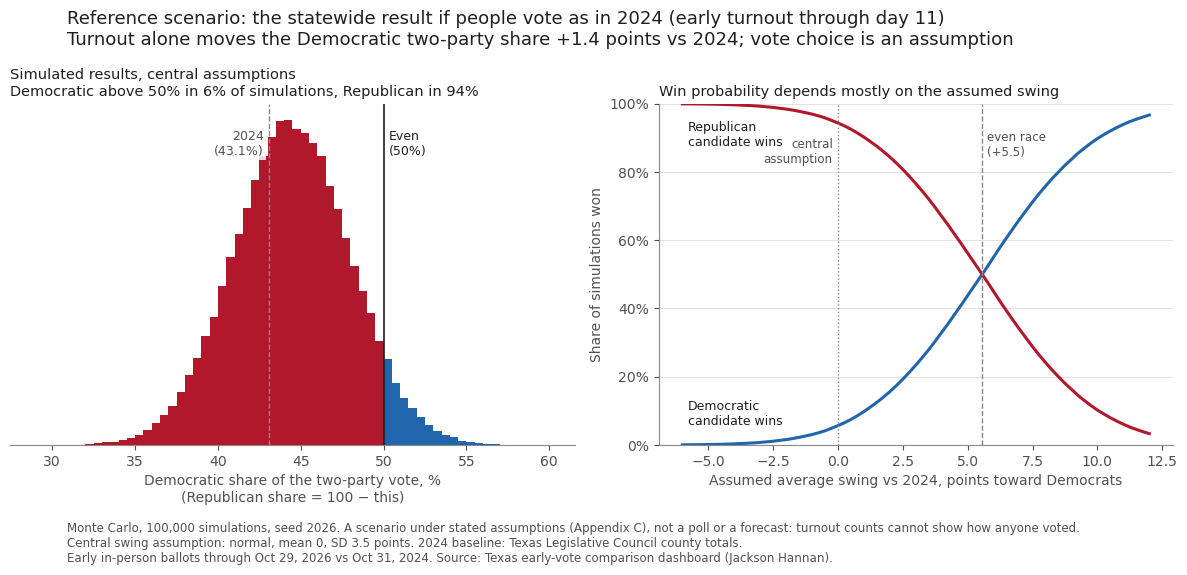

In [16]:
swing_grid = np.arange(-6, 12.01, 0.25)
dem_wins_curve = np.array([(dem_share(swing_mean=m) > 50).mean() for m in swing_grid])

fig, (left, right) = plt.subplots(
    1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.1, 1]}
)
bins = np.arange(np.floor(scenario.min()), np.ceil(scenario.max()) + 0.5, 0.5)
heights, edges, bars = left.hist(scenario, bins=bins, zorder=3)
# 50 is a bin edge, so every bar sits on one side: blue above 50%, red below.
for bar, low_edge in zip(bars, edges[:-1]):
    bar.set_facecolor(DEM_BLUE if low_edge >= 50 else REP_RED)
left.axvline(50, color=INK, lw=1.2, zorder=4)
left.axvline(100 * baseline, color=MUTED, lw=1, ls="--", zorder=4)
left.text(50.3, heights.max() * 0.97, "Even\n(50%)", color=INK, fontsize=9, va="top")
left.text(
    100 * baseline - 0.3,
    heights.max() * 0.97,
    f"2024\n({100 * baseline:.1f}%)",
    color=INK_2,
    fontsize=9,
    va="top",
    ha="right",
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5},
    zorder=5,
)
left.set_yticks([])
left.spines["left"].set_visible(False)
left.set_xlabel(
    "Democratic share of the two-party vote, %\n(Republican share = 100 − this)"
)
left.set_title(
    f"Simulated results, central assumptions\nDemocratic above 50% in {p_dem:.0%} of "
    f"simulations, Republican in {p_rep:.0%}",
    fontsize=10.5,
    color=INK,
    loc="left",
)

right.grid(axis="y", color=GRID, lw=0.8)
right.set_axisbelow(True)
right.plot(swing_grid, 100 * dem_wins_curve, color=DEM_BLUE, lw=2.2)
right.plot(swing_grid, 100 * (1 - dem_wins_curve), color=REP_RED, lw=2.2)
right.text(
    swing_grid[0] + 0.2,
    100 * dem_wins_curve[0] + 5,
    "Democratic\ncandidate wins",
    color=INK,
    ha="left",
    va="bottom",
    fontsize=9,
)
right.text(
    swing_grid[0] + 0.2,
    100 * (1 - dem_wins_curve[0]) - 5,
    "Republican\ncandidate wins",
    color=INK,
    ha="left",
    va="top",
    fontsize=9,
)
right.axvline(SWING_VS_2024[0], color=MUTED, lw=1, ls=":")
right.axvline(even_swing, color=MUTED, lw=1, ls="--")
right.text(
    SWING_VS_2024[0] - 0.2,
    86,
    "central\nassumption",
    color=INK_2,
    fontsize=8.5,
    ha="right",
    va="center",
)
right.text(
    even_swing + 0.2,
    88,
    f"even race\n({even_swing:+.1f})".replace("-", "−"),
    color=INK_2,
    fontsize=8.5,
    ha="left",
    va="center",
)
right.set_ylim(0, 100)
right.yaxis.set_major_formatter(PercentFormatter(decimals=0))
right.set_xlabel("Assumed average swing vs 2024, points toward Democrats")
right.set_ylabel("Share of simulations won")
right.set_title(
    "Win probability depends mostly on the assumed swing",
    fontsize=10.5,
    color=INK,
    loc="left",
)

fig.suptitle(
    f"Reference scenario: the statewide result if people vote as in 2024 (early turnout through "
    f"day {day})\n"
    f"Turnout alone moves the Democratic two-party share "
    + f"{turnout_part:+.1f}".replace("-", "−")
    + " points vs 2024; vote choice is an assumption",
    x=0.06,
    ha="left",
    fontsize=13,
    color=INK,
)
fig.tight_layout()
fig.text(
    0.06,
    -0.005,
    f"Monte Carlo, {SCENARIO_DRAWS:,} simulations, seed {SCENARIO_SEED}. A scenario under "
    "stated assumptions (Appendix C), not a poll or a forecast: turnout counts cannot show "
    "how anyone voted.\nCentral swing assumption: normal, mean "
    f"{SWING_VS_2024[0]:g}, SD {SWING_VS_2024[1]:g} points. 2024 baseline: Texas "
    "Legislative Council county totals.\n" + SOURCE,
    fontsize=8.5,
    color=INK_2,
    ha="left",
    va="top",
)
fig.savefig(
    OUTPUT_DIRECTORY / "chart4_reference_scenario.png", dpi=200, bbox_inches="tight"
)
fig.savefig(OUTPUT_DIRECTORY / "chart4_reference_scenario.svg", bbox_inches="tight")
plt.show()

### The projection: vote choice from the polls

This model starts from each race's polling average, which measures vote choice directly, and adds a polling error and the uncertainty about the third-party vote. It then splits the change since 2024 into G, I, T and R, using the identity above. The poll numbers are a dated snapshot written into the next cell; update them before re-sharing.

| # | Assumption | Value used | Why |
|---|---|---|---|
| P1 | The races | U.S. Senate and governor, each modeled separately. The winner is the major candidate with more votes; Texas has no runoff in the general election. | The polls put the two races about 3 points apart. |
| P2 | Poll averages | U.S. Senate: Talarico (D) 49.6%, Paxton (R) 46.4%, which is 51.7% Democratic of the two-party vote ([270toWin](https://www.270towin.com/2026-senate-polls/texas), 8 polls, Oct 30, 2026). Governor: Hinojosa (D) 46.2%, Abbott (R) 48.8%, which is 48.6% Democratic ([PollCheck](https://www.pollcheck.co.uk/us-midterms-2026/governor/texas), Oct 29, 2026). | The latest averages available when this was written. |
| P3 | Polling error | Normal, with SD 2.5 points of two-party share (about 5 points on the margin) and mean 0. Both races get the same draw. | In 2024, polls of competitive states missed the margin by 2.9 points on average and overstated the Democrat by 2.7 ([538](https://abcnews.com/538/2024-polls-accurate-underestimated-trump/story?id=115652118)). Texas is polled less, and midterms are harder to poll. The sensitivity table shows a biased error. |
| P4 | G: where people vote | The turnout effect from the reference scenario, using the same simulation draws. | Measured from the early-vote data. |
| P5 | Independents' 2024 share of the electorate | Uniform, 20% to 36%. | 36% said "independent or something else" in the 2024 exit poll ([ABC News](https://abcnews.go.com/Elections/texas-exit-polls-2024-us-presidential-election-results-analysis)). Pre-election surveys usually count fewer independents, so the lower end allows for the two different definitions. |
| P6 | Independents' 2024 vote | 49.5% Democratic of the two-party vote (Harris 48, Trump 49), SD 2. | 2024 exit poll. |
| P7 | Independents' 2026 vote | U.S. Senate 65.2% Democratic (Talarico 60, Paxton 32). Governor 60.4% Democratic (Hinojosa 55, Abbott 36). SD 4. | Independent likely voters in the [UH Hobby School's Texas Votes 2026](https://www.uh.edu/hobby/texas2026/) survey, Oct 10–14, 2026, as reported by [CBS Austin](https://cbsaustin.com/newsletter-daily/new-poll-shows-independent-voters-more-likely-to-support-dems-in-texas-elections). |
| P8 | New voters the polls miss | `NEW_VOTER_LIFT` = 0 points. | See rule 3 above. The sensitivity table shows other values. |
| P9 | Third-party candidates' share of the vote | 2024: Stein, Oliver and write-ins took 1.4% of the presidential vote ([official results](https://en.wikipedia.org/wiki/2024_United_States_presidential_election_in_Texas)). 2026 as polled: the Libertarian's share of decided voters, Ted Brown 3% for U.S. Senate (UH Hobby School survey, which had 3% undecided) and Pat Dixon 2.2% for governor (PollCheck average). Undecided voters are split like decided ones. Final share = polled share + `THIRD_PARTY_GAP` (0) + an error with SD 1 point, the same draw for both races. | Third-party candidates often finish away from their poll numbers. The sensitivity table shows a fade and a rise. |
| P10 | Which major candidate the third-party votes come from | 65% from the Republican and 35% from the Democrat, SD 10 points, the same draw for both races. It applies to third-party votes beyond the 2024 share (term T) and to any gap between the polled and the final third-party share (the outcome). | An assumption, not a measurement: Libertarian candidates are generally expected to draw more from Republicans. The sensitivity table shows 50/50 and 80/20. |

**What R, "everything else", contains.** R is not modeled directly. It is the leftover: the poll-implied change minus G, I and T, so it holds whatever the polls show that the turnout data, the independent vote and the third-party pull do not explain.

1. **Partisans changing sides.** 2024 Trump voters who now back the Democrat, and 2024 Harris voters who now back the Republican. These are self-identified Republicans and Democrats; independents are in I.
2. **Candidate effects compared with the 2024 baseline.** The baseline is the presidential race, so a different matchup, incumbency (Abbott) and ticket-splitting all land here. For scale: in 2024, Cruz ran about 5 points behind Trump on the margin on the same ballot.
3. **Who votes inside a precinct.** G only captures which precincts turn out more, assuming each votes as it did in 2024. If Democrats turn out more than Republicans within a mixed precinct, that shows up in R. This covers enthusiasm gaps, the usual midterm penalty for the president's party, and new or infrequent voters.
4. **Extra independents.** I holds independents at their 2024 share of the electorate. When there are more of them inside a precinct, that effect lands in R (by design, so it isn't counted twice).
5. **Errors in the other terms, plus small interactions.** The total is fixed by the poll, so any error in G, I or T gets absorbed here. For example, the exit poll and the UH survey define "independent" differently. That is why R's range is wide: it mirrors the uncertainty in the other terms.

R does not contain the polling error (that is the range of outcomes), `NEW_VOTER_LIFT` (added on top of the poll, 0 by default) or the third-party pull (T).

**Charts and tables.** Chart 5 shows the split for both races on the two-party scale. Chart 6 shows it on the scale of all votes, with a step for what the third-party candidates take from the Democrat; on that scale the winning line is a tie with the Republican rather than 50%. Chart 7 shows each race on its own, with the simulated outcomes as a histogram on the side that shares the vertical axis. Two sensitivity tables follow the next cell: polling bias against the lift from new voters, and the third-party gap against the 65/35 split.

**How to read it.** The projection's win probabilities are only as good as the polls. The split into G, I, T and R is approximate. The exit poll and the 2026 survey define independents differently, which is why P5 is wide, and R is a leftover, so it absorbs any error in the other terms as well as everything else.

In [17]:
# --- Projection inputs: a dated snapshot of public polling (update before re-sharing) -------
POLLS_AS_OF = "2026-10-30"
# P2: Democratic and Republican candidate, % of respondents, in each race's polling average.
POLL_AVERAGES = {"U.S. Senate": (49.6, 46.4), "Governor": (46.2, 48.8)}
# P3: polling error in two-party points: SD, and mean (negative = polls overstate Democrats).
POLL_ERROR_SD = 2.5
POLL_BIAS = 0.0
# P5: independents' share of the 2024 electorate, uniform range.
INDEPENDENT_SHARE_2024 = (0.20, 0.36)
# P6, P7: independents' Democratic share of the two-party vote, %, and the SD of each.
INDEPENDENT_DEM_2024 = 100 * 48 / (48 + 49)
INDEPENDENT_DEM_2026 = {
    "U.S. Senate": 100 * 60 / (60 + 32),
    "Governor": 100 * 55 / (55 + 36),
}
INDEPENDENT_SD_2024 = 2.0
INDEPENDENT_SD_2026 = 4.0
# P8: extra points toward Democrats from new voters the polls miss. 0 = none (see rule 3).
NEW_VOTER_LIFT = 0.0
# P9: third-party candidates, % of all votes. 2024: Stein, Oliver and write-ins, 159,827 of
# 11,388,674 presidential votes. 2026: the Libertarian's share of decided voters in the polls.
THIRD_PARTY_2024 = 100 * 159_827 / 11_388_674
THIRD_PARTY_2026 = {"U.S. Senate": 100 * 3 / 97, "Governor": 100 * 2.2 / 97.2}
# P9: final third-party share minus the polled share, in points: expected value, and SD.
THIRD_PARTY_GAP = 0.0
THIRD_PARTY_GAP_SD = 1.0
# P10: share of third-party votes that come from the Republican: expected value, and SD.
THIRD_PARTY_FROM_REP = 0.65
THIRD_PARTY_FROM_REP_SD = 0.10

rng_b = np.random.default_rng(SCENARIO_SEED + 1)
# G: the same draws as the reference scenario.
where_people_vote = carry_over() * turnout_effect
independent_share = rng_b.uniform(*INDEPENDENT_SHARE_2024, SCENARIO_DRAWS)
independent_2024 = INDEPENDENT_DEM_2024 + INDEPENDENT_SD_2024 * rng_b.normal(
    size=SCENARIO_DRAWS
)
# One polling-error draw per simulation, shared by both races.
poll_error_z = rng_b.normal(size=SCENARIO_DRAWS)
independent_2026_z = {race: rng_b.normal(size=SCENARIO_DRAWS) for race in POLL_AVERAGES}
# One third-party gap and one split per simulation, shared by both races.
rng_third = np.random.default_rng(SCENARIO_SEED + 2)
third_gap_z = rng_third.normal(size=SCENARIO_DRAWS)
from_rep_z = rng_third.normal(size=SCENARIO_DRAWS)


def share_from_rep(mean=THIRD_PARTY_FROM_REP):
    """Simulated share of third-party votes that come from the Republican, 0 to 1."""
    return np.clip(mean + THIRD_PARTY_FROM_REP_SD * from_rep_z, 0, 1)


def third_party_pull(poll_share, polled_third, from_rep):
    """T: how far the third-party vote beyond 2024's share raises the Democrat's two-party
    share, because more of it comes from the Republican. It is inside the poll average:
    this undoes it to find the two-party share without it, and returns the difference."""
    extra = polled_third - THIRD_PARTY_2024
    dem = poll_share * (1 - polled_third / 100) + (1 - from_rep) * extra
    rep = (100 - poll_share) * (1 - polled_third / 100) + from_rep * extra
    return poll_share - 100 * dem / (dem + rep)


def projected_votes(
    poll_share,
    polled_third,
    bias=POLL_BIAS,
    lift=NEW_VOTER_LIFT,
    gap=THIRD_PARTY_GAP,
    from_rep=THIRD_PARTY_FROM_REP,
):
    """Simulated % of all votes for the Democrat, the Republican and the third-party
    candidates. The poll average plus a polling error sets the two-party split among the
    polled voters. Then the voters who leave the third-party candidates (or join them)
    compared with their polled share move to (or from) the Republican at the given split."""
    two_party = poll_share + bias + lift + POLL_ERROR_SD * poll_error_z
    third = np.maximum(polled_third + gap + THIRD_PARTY_GAP_SD * third_gap_z, 0.2)
    # Positive: third-party voters returning to a major candidate.
    moved = polled_third - third
    split = share_from_rep(from_rep)
    dem = two_party * (1 - polled_third / 100) + (1 - split) * moved
    rep = (100 - two_party) * (1 - polled_third / 100) + split * moved
    return dem, rep, third


projection = {}
for race, (dem_pct, rep_pct) in POLL_AVERAGES.items():
    poll_share = 100 * dem_pct / (dem_pct + rep_pct)
    polled_third = THIRD_PARTY_2026[race]
    independent_2026 = (
        INDEPENDENT_DEM_2026[race] + INDEPENDENT_SD_2026 * independent_2026_z[race]
    )
    # I: the change in independents' vote, at their 2024 share of the electorate.
    independents = independent_share * (independent_2026 - independent_2024)
    # T: the third-party candidates drawing more from the Republican than from the Democrat.
    third_pull = third_party_pull(poll_share, polled_third, share_from_rep())
    # R: whatever is left of the poll-implied change once G, I and T are taken out.
    everything_else = (
        poll_share - 100 * baseline - where_people_vote - independents - third_pull
    )
    # The split is exact: G + I + T + R is the poll-implied change; none is added on top.
    assert np.allclose(
        100 * baseline
        + where_people_vote
        + independents
        + third_pull
        + everything_else,
        poll_share,
    )
    dem, rep, third = projected_votes(poll_share, polled_third)
    assert np.allclose(dem + rep + third, 100)
    projection[race] = {
        "poll_share": poll_share,
        "polled_third": polled_third,
        "G": where_people_vote,
        "I": independents,
        "T": third_pull,
        "R": everything_else,
        "from_rep": share_from_rep(),
        "dem_all_votes": dem,
        "rep_all_votes": rep,
        "third_party": third,
        "outcome": 100 * dem / (dem + rep),
        "dem_wins": float((dem > rep).mean()),
        "rep_wins": float((rep > dem).mean()),
        "all_votes_at_poll": {
            "Democratic": poll_share * (1 - polled_third / 100),
            "Republican": (100 - poll_share) * (1 - polled_third / 100),
            "Third party": polled_third,
        },
    }


def dem_win_pct(race, **settings):
    """Democratic candidate wins, % of simulations, under other settings."""
    res = projection[race]
    dem, rep, _ = projected_votes(res["poll_share"], res["polled_third"], **settings)
    return 100 * (dem > rep).mean()


def median_split(res):
    """G, I and T at their medians, and R as what is left of the poll-implied change, so
    the four add up exactly. Every headline number and chart uses this split."""
    split = {k: float(np.median(res[k])) for k in ("G", "I", "T")}
    split["R"] = res["poll_share"] - 100 * baseline - sum(split.values())
    return split


projection_table = pd.concat(
    {
        race: pd.DataFrame(
            {
                "Change from 2024 implied by the poll average": spread(
                    np.full(1, res["poll_share"] - 100 * baseline)
                ),
                "G: where people vote (early-vote data)": spread(res["G"]),
                "I: how independents vote": spread(res["I"]),
                "T: third-party pull (more of it from the Republican)": spread(
                    res["T"]
                ),
                "R: everything else (leftover)": spread(res["R"]),
                "Simulated Democratic two-party share, %": spread(res["outcome"]),
                "Simulated Democratic share of all votes, %": spread(
                    res["dem_all_votes"]
                ),
                "Simulated Republican share of all votes, %": spread(
                    res["rep_all_votes"]
                ),
                "Simulated third-party share of all votes, %": spread(
                    res["third_party"]
                ),
            }
        ).T
        for race, res in projection.items()
    },
    names=["race", "measure"],
)
projection_sensitivity = pd.DataFrame(
    {
        (race, f"lift {lift:g}"): [
            dem_win_pct(race, bias=b, lift=lift) for b in (-2.0, -1.0, 0.0, 1.0)
        ]
        for race in projection
        for lift in (0.0, 0.5, 1.0, 2.0)
    },
    index=pd.Index(
        [-2.0, -1.0, 0.0, 1.0],
        name="Polling bias, points toward Democrats (negative = polls overstate them)",
    ),
)
THIRD_PARTY_GAPS = [-2.0, -1.0, 0.0, 1.0, 2.0]
projection_third_party_sensitivity = pd.DataFrame(
    {
        (race, f"{100 * split:.0f}% from R"): [
            dem_win_pct(race, gap=g, from_rep=split) for g in THIRD_PARTY_GAPS
        ]
        for race in projection
        for split in (0.5, 0.65, 0.8)
    },
    index=pd.Index(
        THIRD_PARTY_GAPS,
        name="Final third-party share minus the polled share, points (negative = fades)",
    ),
)

print(f"The projection, polls as of {POLLS_AS_OF}, {SCENARIO_DRAWS:,} simulations.")
for race, res in projection.items():
    parts = median_split(res)
    print(
        f"{race}: the polls put the Democrat at {res['poll_share']:.1f}% of the two-party vote "
        f"({res['poll_share'] - 100 * baseline:+.1f} points from 2024). Of that change, "
        f"{parts['G']:+.1f} is where people vote, {parts['I']:+.1f} how independents vote, "
        f"{parts['T']:+.1f} the third-party candidates drawing more from the Republican, "
        f"and {parts['R']:+.1f} everything else. The "
        f"Democratic candidate wins {res['dem_wins']:.0%} of simulations, the Republican "
        f"{res['rep_wins']:.0%}."
    )
display(projection_table.round(2))
print(
    "Democratic candidate wins, % of simulations, by polling bias (rows) and the extra lift "
    "from voters the polls miss (columns):"
)
display(projection_sensitivity.round(1))
print(
    "Democratic candidate wins, % of simulations, by how far the third-party candidates end "
    "from their poll share (rows) and the share of their votes that come from the Republican "
    "(columns):"
)
display(projection_third_party_sensitivity.round(1))

The projection, polls as of 2026-10-30, 100,000 simulations.
U.S. Senate: the polls put the Democrat at 51.7% of the two-party vote (+8.6 points from 2024). Of that change, +1.4 is where pe
ople vote, +4.3 how independents vote, +0.3 the third-party candidates drawing more from the Republican, and +2.6 everything els
e. The Democratic candidate wins 75% of simulations, the Republican 25%.
Governor: the polls put the Democrat at 48.6% of the two-party vote (+5.6 points from 2024). Of that change, +1.4 is where peopl
e vote, +3.0 how independents vote, +0.1 the third-party candidates drawing more from the Republican, and +1.1 everything else.
The Democratic candidate wins 29% of simulations, the Republican 71%.


median     5%  \
race        measure                                                             
U.S. Senate Change from 2024 implied by the poll average          8.61   8.61   
            G: where people vote (early-vote data)                1.40   0.96   
            I: how independents vote                              4.31   2.18   
            T: third-party pull (more of it from the Republ...    0.29   0.00   
            R: everything else (leftover)                         2.60  -0.11   
            Simulated Democratic two-party share, %              51.67  47.55   
            Simulated Democratic share of all votes, %           50.07  46.04   
            Simulated Republican share of all votes, %           46.84  42.70   
            Simulated third-party share of all votes, %           3.08   1.44   
Governor    Change from 2024 implied by the poll average          5.57   5.57   
            G: where people vote (early-vote data)                1.40   0.96   
            I: how independents vote                              2.99   0.96   
            T: third-party pull (more of it from the Republ...    0.12  -0.03   
            R: everything else (leftover)                         1.05  -1.43   
            Simulated Democratic two-party share, %              48.64  44.52   
            Simulated Democratic share of all votes, %           47.53  43.47   
            Simulated Republican share of all votes, %           50.21  46.03   
            Simulated third-party share of all votes, %           2.25   0.61   

                                                                  95%  
race        measure                                                    
U.S. Senate Change from 2024 implied by the poll average         8.61  
            G: where people vote (early-vote data)               1.85  
            I: how independents vote                             6.98  
            T: third-party pull (more of it from the Republ...   0.57  
            R: everything else (leftover)                        4.80  
            Simulated Democratic two-party share, %             55.82  
            Simulated Democratic share of all votes, %          54.10  
            Simulated Republican share of all votes, %          50.98  
            Simulated third-party share of all votes, %          4.74  
Governor    Change from 2024 implied by the poll average         5.57  
            G: where people vote (early-vote data)               1.85  
            I: how independents vote                             5.45  
            T: third-party pull (more of it from the Republ...   0.26  
            R: everything else (leftover)                        3.14  
            Simulated Democratic two-party share, %             52.78  
            Simulated Democratic share of all votes, %          51.59  
            Simulated Republican share of all votes, %          54.37  
            Simulated third-party share of all votes, %          3.91

Democratic candidate wins, % of simulations, by polling bias (rows) and the extra lift from voters the polls miss (columns):


U.S. Senate           \
                                                        lift 0 lift 0.5   
Polling bias, points toward Democrats (negative...                        
-2.0                                                      44.9     52.6   
-1.0                                                      60.4     67.9   
 0.0                                                      74.7     80.5   
 1.0                                                      85.5     89.6   

                                                                 Governor  \
                                                   lift 1 lift 2   lift 0   
Polling bias, points toward Democrats (negative...                          
-2.0                                                 60.4   74.7      9.0   
-1.0                                                 74.7   85.5     17.2   
 0.0                                                 85.5   92.8     29.4   
 1.0                                                 92.8   96.9     44.3   

                                                                           
                                                   lift 0.5 lift 1 lift 2  
Polling bias, points toward Democrats (negative...                         
-2.0                                                   12.7   17.2   29.4  
-1.0                                                   22.8   29.4   44.3  
 0.0                                                   36.7   44.3   59.9  
 1.0                                                   52.1   59.9   74.2

Democratic candidate wins, % of simulations, by how far the third-party candidates end from their poll share (rows) and the shar
e of their votes that come from the Republican (columns):


U.S. Senate             \
                                                    50% from R 65% from R   
Final third-party share minus the polled share,...                          
-2.0                                                      74.6       70.7   
-1.0                                                      74.6       72.6   
 0.0                                                      74.7       74.7   
 1.0                                                      74.7       76.5   
 2.0                                                      74.6       78.2   

                                                                Governor  \
                                                   80% from R 50% from R   
Final third-party share minus the polled share,...                         
-2.0                                                     66.5       29.4   
-1.0                                                     70.5       29.4   
 0.0                                                     74.5       29.4   
 1.0                                                     78.2       29.4   
 2.0                                                     81.5       29.4   

                                                                          
                                                   65% from R 80% from R  
Final third-party share minus the polled share,...                        
-2.0                                                     26.0       22.9  
-1.0                                                     27.5       25.6  
 0.0                                                     29.4       29.5  
 1.0                                                     31.5       33.8  
 2.0                                                     33.8       38.4

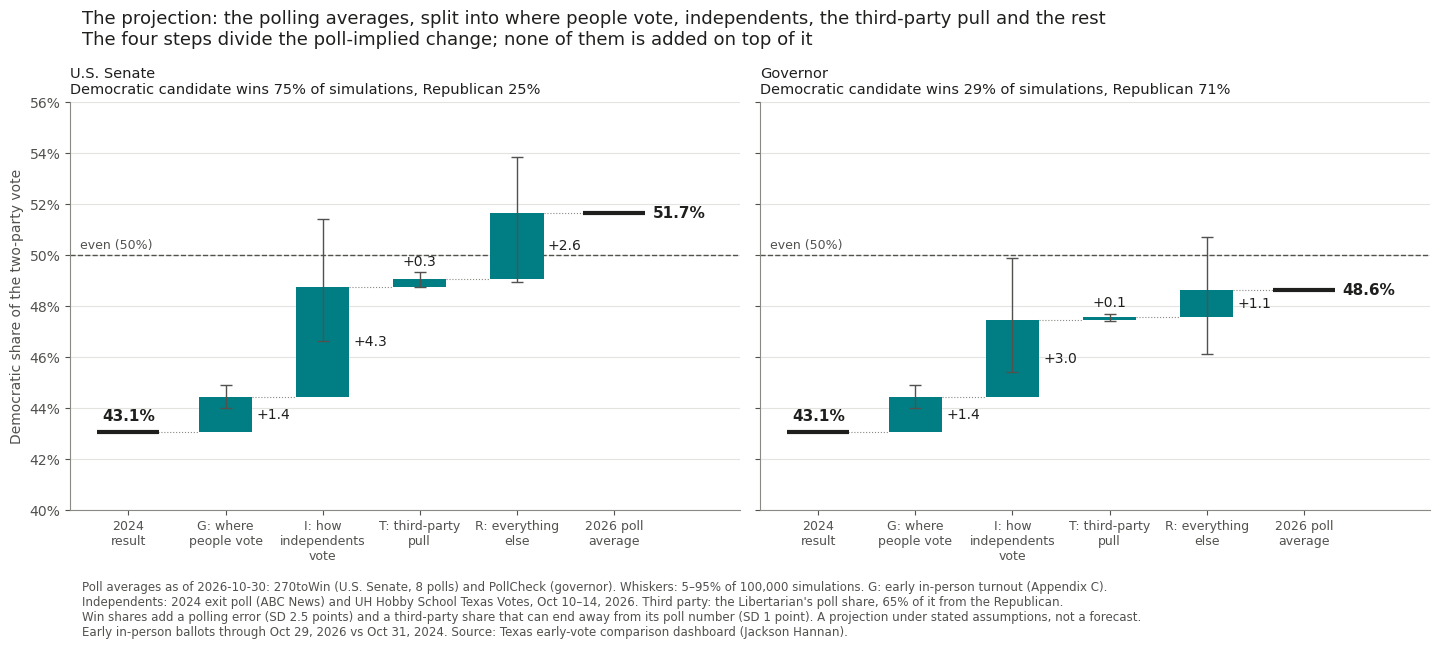

In [18]:
def signed(value, digits=1):
    """'+4.5' or '−1.2', with a typographic minus sign."""
    return f"{value:+.{digits}f}".replace("-", "−")


STEP_NAMES = [
    "2024\nresult",
    "G: where\npeople vote",
    "I: how\nindependents\nvote",
    "T: third-party\npull",
    "R: everything\nelse",
    "2026 poll\naverage",
]


def split_steps(res, scale=1.0):
    """G, I, T and R from median_split, which add up exactly to the poll-implied change.
    Whiskers: each step's 5th and 95th percentile."""
    parts = median_split(res)
    whiskers = [tuple(scale * np.percentile(res[k], [5, 95])) for k in parts]
    return [scale * v for v in parts.values()], whiskers


def waterfall(ax, start, steps, step_names, whiskers=()):
    """Floating bars from a starting level. Each step starts where the last one ended, and
    the first and last levels are drawn as totals. Returns the levels."""
    levels = start + np.concatenate([[0], np.cumsum(steps)])
    last = len(steps) + 1
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.hlines(
        [levels[0], levels[-1]],
        [-0.32, last - 0.32],
        [0.32, last + 0.32],
        color=INK,
        lw=3,
        zorder=4,
    )
    ax.text(
        0,
        levels[0] + 0.35,
        f"{levels[0]:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        last + 0.4,
        levels[-1],
        f"{levels[-1]:.1f}%",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=INK,
    )
    for k, delta in enumerate(steps, start=1):
        ax.bar(
            k,
            delta,
            bottom=levels[k - 1],
            width=0.55,
            color=ACCENT if delta >= 0 else DOTS,
            zorder=3,
        )
        top = max(levels[k - 1], levels[k])
        if k <= len(whiskers):
            low, high = whiskers[k - 1]
            ax.errorbar(
                k,
                levels[k],
                yerr=[[max(delta - low, 0)], [max(high - delta, 0)]],
                color=INK_2,
                lw=1,
                capsize=4,
                zorder=5,
            )
            top = max(top, levels[k - 1] + high)
        # Thin bars get their label above, so it cannot run into the next bar.
        if abs(delta) < 0.5:
            ax.text(
                k,
                top + 0.15,
                signed(delta),
                ha="center",
                va="bottom",
                fontsize=10,
                color=INK,
            )
        else:
            ax.text(
                k + 0.32,
                levels[k - 1] + delta / 2,
                signed(delta),
                ha="left",
                va="center",
                fontsize=10,
                color=INK,
            )
    for k in range(last):
        ax.plot(
            [k + 0.275, k + 0.725],
            [levels[k], levels[k]],
            color=MUTED,
            lw=0.8,
            ls=":",
            zorder=2,
        )
    ax.set_xticks(range(last + 1), step_names)
    ax.tick_params(axis="x", labelsize=9)
    ax.set_xlim(-0.6, last + 1.3)
    return levels


fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True)
for ax, (race, res) in zip(axes, projection.items()):
    steps, whiskers = split_steps(res)
    levels = waterfall(ax, 100 * baseline, steps, STEP_NAMES, whiskers)
    assert np.isclose(levels[-1], res["poll_share"])
    ax.axhline(50, color=INK_2, lw=1, ls="--", zorder=2)
    ax.text(-0.5, 50.15, "even (50%)", va="bottom", ha="left", fontsize=9, color=INK_2)
    ax.set_title(
        f"{race}\nDemocratic candidate wins {res['dem_wins']:.0%} of simulations, "
        f"Republican {res['rep_wins']:.0%}",
        fontsize=10.5,
        color=INK,
        loc="left",
    )
axes[0].set_ylim(40, 56)
axes[0].yaxis.set_major_formatter(PercentFormatter(decimals=0))
axes[0].set_ylabel("Democratic share of the two-party vote")
fig.suptitle(
    "The projection: the polling averages, split into where people vote, independents, the "
    "third-party pull and the rest\n"
    "The four steps divide the poll-implied change; none of them is added on top of it",
    x=0.06,
    ha="left",
    fontsize=13,
    color=INK,
)
fig.tight_layout()
PROJECTION_NOTE = (
    f"Poll averages as of {POLLS_AS_OF}: 270toWin (U.S. Senate, 8 polls) and PollCheck "
    f"(governor). Whiskers: 5–95% of {SCENARIO_DRAWS:,} simulations. G: early in-person "
    "turnout (Appendix C).\nIndependents: 2024 exit poll (ABC News) and UH Hobby School "
    "Texas Votes, Oct 10–14, 2026. Third party: the Libertarian's poll share, "
    f"{100 * THIRD_PARTY_FROM_REP:.0f}% of it from the Republican.\nWin shares add a polling "
    f"error (SD {POLL_ERROR_SD:g} points) and a third-party share that can end away from its "
    f"poll number (SD {THIRD_PARTY_GAP_SD:g} point). A projection under stated assumptions, "
    "not a forecast.\n" + SOURCE
)
fig.text(0.06, -0.005, PROJECTION_NOTE, fontsize=8.5, color=INK_2, ha="left", va="top")
fig.savefig(OUTPUT_DIRECTORY / "chart5_projection.png", dpi=200, bbox_inches="tight")
fig.savefig(OUTPUT_DIRECTORY / "chart5_projection.svg", bbox_inches="tight")
plt.show()

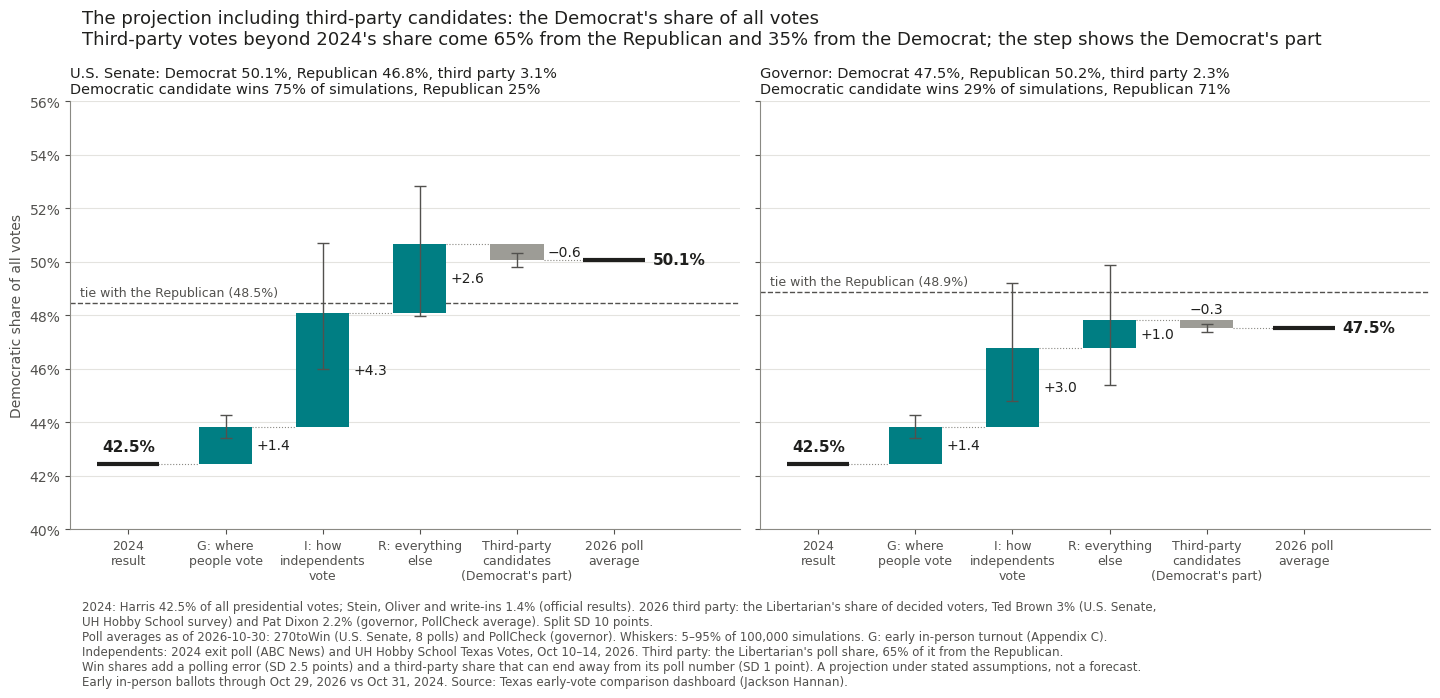

U.S. Senate, all votes at the poll average: Democratic 50.1%, Republican 46.8%, Third party 3.1% (2024: Democratic 42.5%, third
party 1.4%).
Governor, all votes at the poll average: Democratic 47.5%, Republican 50.2%, Third party 2.3% (2024: Democratic 42.5%, third par
ty 1.4%).


In [19]:
# Chart 6: the same split on the scale of all votes. G, I and R move the Democrat's
# two-party share at 2024's third-party share, so they shrink by that share. The last step
# is what the third-party votes beyond 2024's share take from the Democrat: 35% of them.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6), sharey=True)
all_vote_steps = [
    "2024\nresult",
    "G: where\npeople vote",
    "I: how\nindependents\nvote",
    "R: everything\nelse",
    "Third-party\ncandidates\n(Democrat's part)",
    "2026 poll\naverage",
]
start_all = 100 * baseline * (1 - THIRD_PARTY_2024 / 100)
for ax, (race, res) in zip(axes, projection.items()):
    shares = res["all_votes_at_poll"]
    extra = res["polled_third"] - THIRD_PARTY_2024
    steps, whiskers = split_steps(res, scale=1 - THIRD_PARTY_2024 / 100)
    # Keep G, I and R; on this scale T is replaced by the third-party step below.
    steps, whiskers = [steps[0], steps[1], steps[3]], [whiskers[0], whiskers[1], whiskers[3]]
    third_step = shares["Democratic"] - start_all - sum(steps)
    # Exact by construction; the check confirms it is the Democrat's part of the extra vote.
    assert np.isclose(
        third_step, -(1 - np.median(res["from_rep"])) * extra, atol=0.01
    ), third_step
    third_range = tuple(np.percentile(-(1 - res["from_rep"]) * extra, [5, 95]))
    levels = waterfall(
        ax,
        start_all,
        steps + [third_step],
        all_vote_steps,
        whiskers + [third_range],
    )
    assert np.isclose(levels[-1], shares["Democratic"])
    tie = (100 - shares["Third party"]) / 2
    ax.axhline(tie, color=INK_2, lw=1, ls="--", zorder=2)
    ax.text(
        -0.5,
        tie + 0.15,
        f"tie with the Republican ({tie:.1f}%)",
        va="bottom",
        ha="left",
        fontsize=9,
        color=INK_2,
    )
    ax.set_title(
        f"{race}: Democrat {shares['Democratic']:.1f}%, Republican {shares['Republican']:.1f}%, "
        f"third party {shares['Third party']:.1f}%\nDemocratic candidate wins "
        f"{res['dem_wins']:.0%} of simulations, Republican {res['rep_wins']:.0%}",
        fontsize=10.5,
        color=INK,
        loc="left",
    )
axes[0].set_ylim(40, 56)
axes[0].yaxis.set_major_formatter(PercentFormatter(decimals=0))
axes[0].set_ylabel("Democratic share of all votes")
fig.suptitle(
    "The projection including third-party candidates: the Democrat's share of all votes\n"
    f"Third-party votes beyond 2024's share come {100 * THIRD_PARTY_FROM_REP:.0f}% from the "
    f"Republican and {100 * (1 - THIRD_PARTY_FROM_REP):.0f}% from the Democrat; the "
    "step shows the Democrat's part",
    x=0.06,
    ha="left",
    fontsize=13,
    color=INK,
)
fig.tight_layout()
fig.text(
    0.06,
    -0.005,
    f"2024: Harris {start_all:.1f}% of all presidential votes; Stein, Oliver and write-ins "
    f"{THIRD_PARTY_2024:.1f}% (official results). 2026 third party: the Libertarian's share of "
    "decided voters, Ted Brown 3% (U.S. Senate,\nUH Hobby School survey) and Pat Dixon 2.2% "
    f"(governor, PollCheck average). Split SD {100 * THIRD_PARTY_FROM_REP_SD:.0f} points.\n"
    + PROJECTION_NOTE,
    fontsize=8.5,
    color=INK_2,
    ha="left",
    va="top",
)
fig.savefig(
    OUTPUT_DIRECTORY / "chart6_projection_all_votes.png", dpi=200, bbox_inches="tight"
)
fig.savefig(OUTPUT_DIRECTORY / "chart6_projection_all_votes.svg", bbox_inches="tight")
plt.show()
for race, res in projection.items():
    shares = res["all_votes_at_poll"]
    print(
        f"{race}, all votes at the poll average: "
        + ", ".join(f"{k} {v:.1f}%" for k, v in shares.items())
        + f" (2024: Democratic {start_all:.1f}%, third party {THIRD_PARTY_2024:.1f}%)."
    )

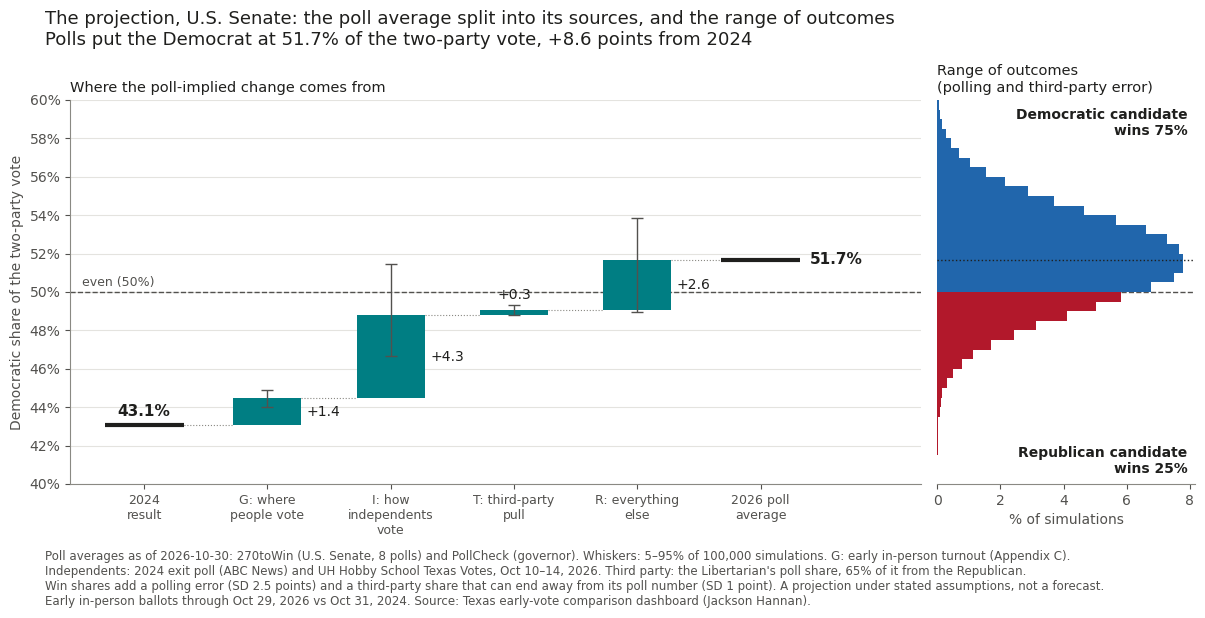

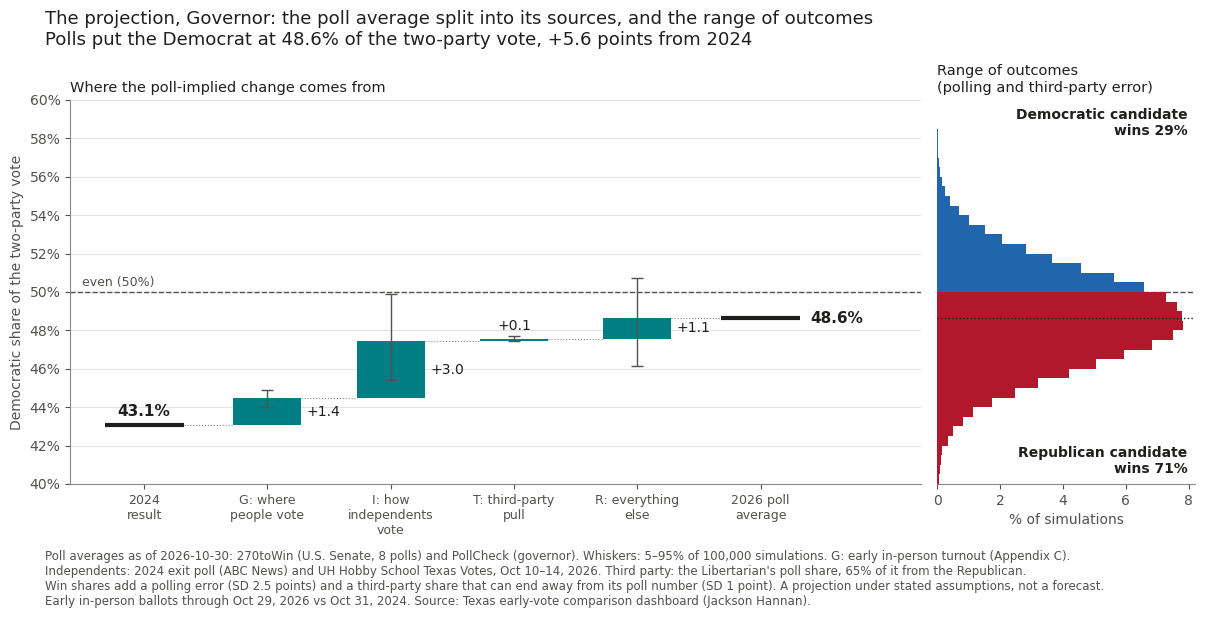

In [20]:
for race, res in projection.items():
    fig, (ax, side) = plt.subplots(
        1,
        2,
        figsize=(12.5, 6),
        sharey=True,
        gridspec_kw={"width_ratios": [3.3, 1], "wspace": 0.03},
    )
    steps, whiskers = split_steps(res)
    waterfall(ax, 100 * baseline, steps, STEP_NAMES, whiskers)
    ax.set_title(
        "Where the poll-implied change comes from", fontsize=10.5, color=INK, loc="left"
    )
    ax.text(-0.5, 50.15, "even (50%)", va="bottom", ha="left", fontsize=9, color=INK_2)
    ax.set_ylabel("Democratic share of the two-party vote")

    # The simulated outcomes, as a histogram turned on its side to share the y-axis.
    # 50 is a bin edge, so no bin straddles it.
    edges = np.arange(36, 64.01, 0.5)
    counts, _ = np.histogram(res["outcome"], bins=edges)
    mids = (edges[:-1] + edges[1:]) / 2
    side.barh(
        mids,
        100 * counts / counts.sum(),
        height=0.5,
        color=np.where(mids > 50, DEM_BLUE, REP_RED),
        zorder=3,
    )
    # The median simulated outcome, which sits at the poll average.
    side.axhline(np.median(res["outcome"]), color=INK, lw=1, ls=":", zorder=4)
    side.text(
        0.97,
        0.98,
        f"Democratic candidate\nwins {res['dem_wins']:.0%}",
        transform=side.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        color=INK,
        fontweight="bold",
    )
    side.text(
        0.97,
        0.02,
        f"Republican candidate\nwins {res['rep_wins']:.0%}",
        transform=side.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        color=INK,
        fontweight="bold",
    )
    side.set_title(
        "Range of outcomes\n(polling and third-party error)",
        fontsize=10.5,
        color=INK,
        loc="left",
    )
    side.set_xlabel("% of simulations")
    side.tick_params(axis="y", left=False)
    side.spines["left"].set_visible(False)
    for axis in (ax, side):
        axis.axhline(50, color=INK_2, lw=1, ls="--", zorder=2)
    ax.set_ylim(40, 60)
    ax.set_yticks(np.arange(40, 60.1, 2))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    fig.suptitle(
        f"The projection, {race}: the poll average split into its sources, and the range of "
        f"outcomes\nPolls put the Democrat at {res['poll_share']:.1f}% of the two-party vote, "
        f"{signed(res['poll_share'] - 100 * baseline)} points from 2024",
        x=0.06,
        ha="left",
        fontsize=13,
        color=INK,
    )
    fig.subplots_adjust(left=0.08, right=0.98, top=0.83, bottom=0.19)
    fig.text(
        0.06, 0.08, PROJECTION_NOTE, fontsize=8.5, color=INK_2, ha="left", va="top"
    )
    slug = "senate" if "Senate" in race else "governor"
    fig.savefig(
        OUTPUT_DIRECTORY / f"chart7_projection_{slug}.png", dpi=200, bbox_inches="tight"
    )
    fig.savefig(OUTPUT_DIRECTORY / f"chart7_projection_{slug}.svg", bbox_inches="tight")
    plt.show()

## Saved files, sources and credits

The cell below saves everything to `analysis_outputs/<date>_day<NN>/` and fills in the summary at the top of the notebook:

- the charts, as PNG and SVG,
- the projection's and the reference scenario's tables (`projection_*.csv` and `reference_scenario_*.csv`),
- `precincts.csv` and `counties.csv` (the Explore tables) and `compared_precincts.parquet`,
- `flagged_precincts.csv` (the data-quality screen),
- the tables behind each step, and `summary.json` with every headline number and the data fingerprints.

| Source | Used for |
| --- | --- |
| [Texas early-vote comparison dashboard](https://jacksonahannan.github.io/early-vote-dashboard/) (Jackson Hannan) | Precinct early-vote counts for both years, 2024↔2026 precinct matching, data-quality reviews |
| [Texas Secretary of State early-voting reports](https://earlyvoting.texas-election.com/Elections/getElectionDetails.do) and county election offices | Original sources of the daily early-vote counts the dashboard compiles |
| Certified 2024 county canvass returns | 2024 presidential results by precinct in 14 counties: Bell, Collin, Dallas, Ellis, Fort Bend, Grayson, Harris, Hays, Hockley, Madison, McLennan, Montgomery, Tarrant and Travis |
| [Texas Legislative Council election data](https://data.capitol.texas.gov/dataset/comprehensive-election-datasets-compressed-format) | 2024 presidential results by precinct in all other counties; 2024 county totals for the coverage check (Step 1); 2024 voter registration, ballots cast and Spanish-surname share by precinct (Step 5) |
| [Texas Legislative Council 2024 VTD population data](https://data.capitol.texas.gov/dataset/vtds) | 2020 Census population and Hispanic share of adults by 2024 precinct (Step 5) |
| [Texas Legislative Council precinct boundaries](https://data.capitol.texas.gov/dataset/precincts) | 2024 general and 2026 primary precinct lines |
| U.S. Election Assistance Commission, EAVS Texas data briefs for [2022](https://www.eac.gov/sites/default/files/2023-10/2022_EAVS_Data_Brief_TX_508c.pdf) and [2024](https://www.eac.gov/sites/default/files/2026-07/2024_EAVS_Data_Brief_TX.pdf) | Share of the final vote cast early in person (Appendix C) |
| Texas Secretary of State statewide election results, 2012–2022 | Past presidential-to-midterm changes (Appendix C) |
| Polling averages: [270toWin](https://www.270towin.com/2026-senate-polls/texas) (U.S. Senate) and [PollCheck](https://www.pollcheck.co.uk/us-midterms-2026/governor/texas) (governor), Oct 29–30, 2026 | The projection's starting point (Appendix C) |
| [ABC News 2024 Texas exit poll](https://abcnews.go.com/Elections/texas-exit-polls-2024-us-presidential-election-results-analysis) and the [UH Hobby School's Texas Votes 2026](https://www.uh.edu/hobby/texas2026/) survey (independents, as reported by [CBS Austin](https://cbsaustin.com/newsletter-daily/new-poll-shows-independent-voters-more-likely-to-support-dems-in-texas-elections)) | Independents' vote in 2024 and 2026 (the projection) |
| [538 on 2024 polling accuracy](https://abcnews.com/538/2024-polls-accurate-underestimated-trump/story?id=115652118) | Size of the polling error (the projection) |
| [2024 Texas presidential results](https://en.wikipedia.org/wiki/2024_United_States_presidential_election_in_Texas) (official canvass) | 2024 third-party share of the vote (the projection, term T and Chart 6) |

In [21]:
import json

sample.to_parquet(OUTPUT_DIRECTORY / "compared_precincts.parquet", index=False)
precinct_table.to_csv(OUTPUT_DIRECTORY / "precincts.csv", index=False)
county_table.to_csv(OUTPUT_DIRECTORY / "counties.csv", index=False)
flagged_table.to_csv(OUTPUT_DIRECTORY / "flagged_precincts.csv", index=False)
coverage.reset_index(drop=True).rename(
    columns={
        "county": "County",
        "harris": "2024 Harris votes",
        "trump": "2024 Trump votes",
        "two_party": "2024 Harris + Trump votes",
        "voters_2024_two_party": "in compared precincts",
        "harris_compared": "Harris votes in compared precincts",
    }
).round(2).to_csv(OUTPUT_DIRECTORY / "county_coverage.csv", index=False)
fifths.to_csv(OUTPUT_DIRECTORY / "fifths.csv")
fits.to_csv(OUTPUT_DIRECTORY / "slope.csv", index=False)
robustness.to_csv(OUTPUT_DIRECTORY / "robustness.csv", index=False)
by_day.to_csv(OUTPUT_DIRECTORY / "fifths_by_day.csv")
scenario_parts.to_csv(OUTPUT_DIRECTORY / "reference_scenario_summary.csv")
scenario_sensitivity.to_csv(
    OUTPUT_DIRECTORY / "reference_scenario_win_share_by_swing.csv"
)
carryover_sensitivity.to_csv(
    OUTPUT_DIRECTORY / "reference_scenario_win_share_by_carryover.csv"
)
projection_table.to_csv(OUTPUT_DIRECTORY / "projection_split.csv")
projection_sensitivity.to_csv(
    OUTPUT_DIRECTORY / "projection_win_share_by_bias_and_lift.csv"
)
projection_third_party_sensitivity.to_csv(
    OUTPUT_DIRECTORY / "projection_win_share_by_third_party.csv"
)


def rounded(values):
    return {k: round(v, 3) if isinstance(v, float) else v for k, v in values.items()}


hispanic_summary = {"status": ethnicity_status}
hispanic_line = f"- **By Hispanic share (Step 5):** {ethnicity_status}."
if ethnic is not None:
    pd.concat(
        {label: ethnic_fifths[column] for column, label in ETHNIC_MEASURES.items()},
        names=["measure", "fifth"],
    ).to_csv(OUTPUT_DIRECTORY / "fifths_by_hispanic_share.csv")
    ethnic_cross.to_csv(
        OUTPUT_DIRECTORY / "turnout_by_2024_vote_and_hispanic_share.csv"
    )
    ethnic_models.to_csv(OUTPUT_DIRECTORY / "hispanic_share_models.csv", index=False)
    surname_fifths = ethnic_fifths["spanish_surname_registered_pct"].turnout_vs_2024_pct
    surname_model = ethnic_models.loc[
        (
            ethnic_models["Hispanic measure"]
            == ETHNIC_MEASURES["spanish_surname_registered_pct"]
        )
        & (ethnic_models.comparison == "all compared precincts")
    ].iloc[0]
    hispanic_summary.update(
        {
            "census_table_sha256": census_sha,
            "registration_table_sha256": registration_sha,
            "turnout_vs_2024_pct_by_spanish_surname_fifth": surname_fifths.round(
                2
            ).tolist(),
            "spanish_surname_slope_per_10_pts_holding_2024_vote": round(
                float(surname_model["per +10 pts Hispanic measure"]), 3
            ),
        }
    )
    hispanic_line = (
        f"- **By Hispanic share (Step 5):** precincts in the least Hispanic fifth are at "
        f"{surname_fifths.iloc[0]:.0f}% of their 2024 pace, the most Hispanic fifth at "
        f"{surname_fifths.iloc[-1]:.0f}% (Spanish-surname share of registered voters). Holding the "
        f"2024 vote fixed: {signed(surname_model['per +10 pts Hispanic measure'])} points of "
        f"turnout vs 2024 per +10 points of Spanish-surname share."
    )

projection_line = " ".join(
    f"{race}: polls put the Democrat at {res['poll_share']:.1f}% of the two-party vote "
    f"({signed(res['poll_share'] - 100 * baseline)} from 2024, split into "
    + ", ".join(f"{k} {signed(v)}" for k, v in median_split(res).items())
    + f"); the Democratic candidate wins "
    f"{res['dem_wins']:.0%} of simulations, the Republican {res['rep_wins']:.0%}. Of all "
    f"votes, including third-party candidates: Democrat "
    f"{res['all_votes_at_poll']['Democratic']:.1f}%, Republican "
    f"{res['all_votes_at_poll']['Republican']:.1f}%, third party "
    f"{res['all_votes_at_poll']['Third party']:.1f}%."
    for race, res in projection.items()
)
harris_pct_compared = 100 * compared_harris / compared_total
harris_pct_rest = 100 * (state_harris - compared_harris) / (state_votes - compared_total)
summary = {
    "data": {
        "load_mode": load_mode,
        "published_generated_at_utc": provenance["published_generated_at_utc"],
        "through_2026": f"{date_2026:%Y-%m-%d}",
        "through_2024": f"{date_2024:%Y-%m-%d}",
        "early_voting_day": day,
        "parquet_sha256": data_sha256,
    },
    "settings": {"cohort": COHORT, "qc_applied": APPLY_QC, "x_spacing": X_SPACING},
    "compared": {
        "precinct_groups": len(sample),
        "counties": int(sample.county_id.nunique()),
        "share_of_2024_two_party_vote": round(covered_share, 4),
        "flagged_by_qc": len(flagged),
        "harris_share_2024_pct_in_compared_precincts": round(harris_pct_compared, 2),
        "harris_share_2024_pct_in_rest_of_texas": round(harris_pct_rest, 2),
        "large_counties_not_compared": missing_large.county.tolist(),
    },
    "turnout_vs_2024_pct": {
        "all": round(overall_pct, 2),
        "trump_won_precincts": round(trump_won_pct, 2),
        "harris_won_precincts": round(harris_won_pct, 2),
        "fifths_by_2024_harris_share": fifths.turnout_vs_2024_pct.round(2).tolist(),
    },
    "share_of_early_ballots_from_trump_won_precincts_pct": {
        "2024": round(trump_share_2024, 2),
        "2026": round(trump_share_2026, 2),
    },
    "slope_per_10_harris_pts": rounded(main_fit),
    "slope_within_county": rounded(county_fit),
    "hispanic_share": hispanic_summary,
    "projection": {
        "note": "Poll-anchored projection (Appendix C). G, I, T and R split the poll-implied change; they are not added to it.",
        "polls_as_of": POLLS_AS_OF,
        "assumptions": {
            "poll_averages_dem_rep_pct": {k: list(v) for k, v in POLL_AVERAGES.items()},
            "poll_error_sd_points": POLL_ERROR_SD,
            "poll_bias_points_toward_dem": POLL_BIAS,
            "independent_share_2024_range": list(INDEPENDENT_SHARE_2024),
            "independent_dem_two_party_pct_2024": round(INDEPENDENT_DEM_2024, 2),
            "independent_dem_two_party_pct_2026": {
                k: round(v, 2) for k, v in INDEPENDENT_DEM_2026.items()
            },
            "new_voter_lift_points": NEW_VOTER_LIFT,
            "third_party_pct_2024": round(THIRD_PARTY_2024, 3),
            "third_party_pct_2026": {k: round(v, 3) for k, v in THIRD_PARTY_2026.items()},
            "third_party_gap_mean_sd_points": [THIRD_PARTY_GAP, THIRD_PARTY_GAP_SD],
            "third_party_share_from_rep_mean_sd": [
                THIRD_PARTY_FROM_REP,
                THIRD_PARTY_FROM_REP_SD,
            ],
        },
        "races": {
            race: {
                "poll_dem_two_party_pct": round(res["poll_share"], 3),
                "split_points_G_I_T_median_R_remainder": {
                    k: round(v, 3) for k, v in median_split(res).items()
                },
                "dem_wins_share_of_simulations": round(res["dem_wins"], 4),
                "rep_wins_share_of_simulations": round(res["rep_wins"], 4),
                "all_votes_pct_at_poll_average": {
                    k: round(v, 3) for k, v in res["all_votes_at_poll"].items()
                },
            }
            for race, res in projection.items()
        },
    },
    "reference_scenario_vote_as_in_2024": {
        "note": "Scenario under the assumptions stated in Appendix C, not a forecast.",
        "assumptions": {
            "draws": SCENARIO_DRAWS,
            "seed": SCENARIO_SEED,
            "county_reporting_sd_pct": COUNTY_REPORTING_SD_PCT,
            "early_in_person_share_of_final_vote_range": list(EARLY_IN_PERSON_SHARE),
            "later_voters_repeat_gap_mean_sd": list(REST_REPEATS_GAP),
            "swing_vs_2024_mean_sd_points_toward_dem": list(SWING_VS_2024),
        },
        "dem_two_party_pct_2024": round(100 * baseline, 3),
        "turnout_effect_points_toward_dem_median": round(turnout_part, 3),
        "dem_two_party_pct": {
            "median": round(float(np.median(scenario)), 3),
            "p5": round(float(np.percentile(scenario, 5)), 3),
            "p95": round(float(np.percentile(scenario, 95)), 3),
        },
        "dem_wins_share_of_simulations": round(float(p_dem), 4),
        "rep_wins_share_of_simulations": round(float(p_rep), 4),
        "uniform_swing_for_even_race_points_toward_dem": round(float(even_swing), 3),
    },
}
(OUTPUT_DIRECTORY / "summary.json").write_text(json.dumps(summary, indent=2))

fifth_list = ", ".join(f"{v:.0f}%" for v in fifths.turnout_vs_2024_pct)
missing_note = (
    " Large counties not compared on this day: "
    + ", ".join(missing_large.county)
    + "."
    if len(missing_large)
    else ""
)
summary_md = f"""**Summary (early-voting day {day}: 2026 through {date_2026:%b %d} vs 2024 through {date_2024:%b %d})**

- **Overall:** compared precincts have cast **{overall_pct:.0f}%** as many early in-person ballots as at this point in 2024.
- **By 2024 vote:** Trump-won precincts are at **{trump_won_pct:.0f}%** of their 2024 pace, Harris-won precincts at **{harris_won_pct:.0f}%**. By fifths of 2024 early voters, from most Trump to most Harris: {fifth_list}.
- **Where ballots come from (where they were cast, not how):** Trump-won precincts cast {trump_share_2024:.0f}% of 2024's early ballots at this point and {trump_share_2026:.0f}% of 2026's.
- **One number:** {signed(main_fit["slope_per_10_pts"])} points of turnout vs 2024 per +10 points of 2024 Harris share (95% range {signed(main_fit["range_low"])} to {signed(main_fit["range_high"])}); {signed(county_fit["slope_per_10_pts"])} comparing precincts within the same county.
{hispanic_line}
- **The projection, vote choice from the polls (Appendix C; polls as of {POLLS_AS_OF}):** {projection_line}
- **Reference scenario, if people vote as in 2024 (Appendix C):** turnout alone moves the statewide Democratic two-party share {signed(turnout_part)} points from 2024's {100 * baseline:.1f}%, to a median of {np.median(scenario):.1f}%. The Democratic candidate is ahead in {p_dem:.0%} of simulations and the Republican in {p_rep:.0%}; an even race would need a uniform swing of {signed(even_swing)} points toward Democrats.
- **Coverage:** {len(sample):,} {UNIT}s in {sample.county_id.nunique()} counties, {covered_share:.0%} of Texas's 2024 Harris + Trump vote. In 2024 Harris won {harris_pct_compared:.0f}% of that vote in the compared precincts and {harris_pct_rest:.0f}% in the rest of Texas, so these figures describe the compared precincts, not the whole state.{missing_note} Data: {load_mode.replace("_", " ")}, sha256 {data_sha256[:12]}.
- **Limits:** places, not people; turnout, not vote choice (the projection and the reference scenario rest on their stated assumptions); 2026 is a midterm and 2024 was a presidential year; early in-person ballots only; day {day} of 12, so the numbers will move.
"""
summary_slot.update(Markdown(summary_md))
print(summary_md)
print("Saved to:", shown(OUTPUT_DIRECTORY))

**Summary (early-voting day 11: 2026 through Oct 29 vs 2024 through Oct 31)**

- **Overall:** compared precincts have cast **84%** as many early in-person ballots as at this point in 2024.
- **By 2024 vote:** Trump-won precincts are at **79%** of their 2024 pace, Harris-won precincts at **91%**. By fifths of 2024 ea
rly voters, from most Trump to most Harris: 72%, 79%, 86%, 89%, 93%.
- **Where ballots come from (where they were cast, not how):** Trump-won precincts cast 64% of 2024's early ballots at this poin
t and 60% of 2026's.
- **One number:** +3.9 points of turnout vs 2024 per +10 points of 2024 Harris share (95% range +3.5 to +4.3); +3.3 comparing pr
ecincts within the same county.
- **By Hispanic share (Step 5):** precincts in the least Hispanic fifth are at 79% of their 2024 pace, the most Hispanic fifth a
t 91% (Spanish-surname share of registered voters). Holding the 2024 vote fixed: +1.4 points of turnout vs 2024 per +10 points o
f Spanish-surname share.
- **The projection,

## License

BSD 3-Clause License

Copyright (c) 2026, Greg Jennings

Redistribution and use in source and binary forms, with or without modification, are permitted provided that the following conditions are met:

1. Redistributions of source code must retain the above copyright notice, this list of conditions and the following disclaimer.

2. Redistributions in binary form must reproduce the above copyright notice, this list of conditions and the following disclaimer in the documentation and/or other materials provided with the distribution.

3. Neither the name of the copyright holder nor the names of its contributors may be used to endorse or promote products derived from this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS" AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.

**Data.** This license covers the notebook's code and text. The embedded early-vote snapshot and the tables the notebook downloads come from the sources credited under "Saved files, sources and credits", which set their own terms.